# Session 10 — The Training Loop, Made to Tell the Truth

The lesson's claim: *every serious training bug is silent, and the loss curve is not going to be the one
that tells you.* This notebook takes a real model and a real training loop and checks each part of the
step by printing and measuring it, instead of trusting it.

| | |
|---|---|
| **Model** | 29.9M-weight Llama-style decoder written from scratch in `model.py` (RMSNorm, RoPE, SwiGLU, tied embeddings) |
| **Data** | TinyStories (real short stories), GPT-2 BPE tokenizer, vocabulary 50,257 |
| **Loop** | AdamW, bf16 mixed precision, gradient accumulation, gradient clipping, padding excluded from the loss |
| **Hardware** | Google Colab, NVIDIA L4 (24 GB, Ada Lovelace, bf16 and fp8 tensor cores) |

| Step | Assignment task | Extra experiments |
|---|---|---|
| 1 | Print every tensor shape in a step, say what each dimension means | parameter count by hand, loss computation unrolled, memory per weight measured |
| 2 | Verify one gradient by hand | six weights across the model, nudge-size sweep in fp32 vs fp64, a whole-model Taylor check |
| 3 | Break gradient accumulation on purpose, plot both curves | proof that correct accumulation equals the full-batch gradient, and that the bug vanishes for equal token counts |
| 4 | Log the grad norm every step, find a step where it moved before the loss | an induced instability, and a bad batch where it does **not** lead |
| 5 | Compute MFU honestly, explain the distance to 40% | matmul speed vs size, roofline view of our matmuls, profiler, four loop configurations |
| 6 | 0.1 by hand in fp32, bf16, fp8 E4M3; pick a training format | encode/decode formulas, conversions between formats, where conversions happen in a step, real-tensor error and underflow |

**Notation used throughout:** $B$ batch size (sequences), $T$ sequence length, $D$ model width (384),
$H$ heads (6), $h_d = D/H$ head width (64), $F$ MLP hidden width (1024), $V$ vocabulary (50,304), $L$ layers (6),
$N$ number of weights.

Runs top to bottom. Every number in the text below a code cell was printed by that cell.

## Setup

The Colab kernel runs on a remote machine, so the next cell writes `model.py` there. It is identical to
`model.py` in this folder.

In [5]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip install -q tiktoken datasets

name, memory.total [MiB], driver_version
NVIDIA L4, 23034 MiB, 580.82.07


In [6]:
%%writefile model.py
"""A small Llama-style decoder-only transformer.

Architecture (same block design as Llama / Qwen / Mistral, at toy scale):

    token ids (B, T)
      -> Embedding                      (B, T, D)
      -> L x Block:
            x = x + Attention(RMSNorm(x))      causal self-attention with RoPE
            x = x + SwiGLU(RMSNorm(x))         gated feed-forward
      -> RMSNorm                         (B, T, D)
      -> LM head (tied to the embedding) (B, T, V)   one score per vocabulary entry

Notation used in every docstring and shape comment:
    B = batch size (number of sequences)    T = sequence length (positions)
    D = d_model (width of the residual)     H = number of attention heads
    hd = D // H (width of one head)         F = d_ff (hidden width of the MLP)
    V = vocab_size                          L = n_layer

Shape tracing: pass `trace=[]` to `GPT.forward` and every intermediate tensor is
appended to it as (name, shape, dim_names, meaning). The notebook prints that list,
so the model code itself carries no print statements.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class Config:
    vocab_size: int = 50304   # GPT-2 has 50,257 tokens; padded up to a multiple of 64 for faster matmuls
    n_layer: int = 6          # L
    n_head: int = 6           # H
    d_model: int = 384        # D  (so hd = 384 / 6 = 64)
    d_ff: int = 1024          # F  (SwiGLU hidden width, about 8/3 * D)
    max_seq: int = 512        # longest sequence RoPE tables are built for
    rope_base: float = 10000.0


def _at_least_fp32(dtype):
    """bf16/fp16 -> fp32, fp32 -> fp32, fp64 -> fp64. Upcast only, never downcast."""
    return torch.promote_types(dtype, torch.float32)


def _rec(trace, name, t, dims, meaning):
    """Append one entry to the shape trace, if tracing is on.

    Example:
        _rec(trace, "embed", x, ("B", "T", "D"), "one vector per token")
        -> trace gets ("embed", (2, 177, 384), ("B", "T", "D"), "one vector per token")
    """
    if trace is not None:
        trace.append((name, tuple(t.shape), dims, meaning))


class RMSNorm(nn.Module):
    """Root-mean-square normalisation: rescale each vector to unit RMS, then by a learned gain.

        y = x / sqrt(mean(x^2) + eps) * weight

    Unlike LayerNorm there is no mean subtraction and no bias, which is cheaper and works as well.
    Computed in at least fp32 even under bf16 autocast, because squaring small bf16 numbers loses precision.

    Example:
        x = [[3.0, 4.0]]          mean(x^2) = (9 + 16) / 2 = 12.5,  rms = 3.536
        RMSNorm(2)(x) = [[0.849, 1.131]]     (weight starts at 1)

    Input (..., D) -> output (..., D), same shape.
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        xf = x.to(_at_least_fp32(x.dtype))     # bf16 -> fp32, but fp64 stays fp64 (Step 2 needs that)
        inv_rms = xf.pow(2).mean(-1, keepdim=True).add(self.eps).rsqrt()
        return (xf * inv_rms).type_as(x) * self.weight


def rope_tables(cfg):
    """Precompute the cos/sin tables for rotary position embeddings (RoPE).

    Each pair of features (2i, 2i+1) inside a head is rotated by angle  pos * theta_i,
    with  theta_i = base^(-2i / hd).  Low i rotates fast (fine position), high i slowly (coarse).

    Returns cos, sin, each of shape (max_seq, hd / 2).
    Example with hd = 4, base = 10000:  theta = [1.0, 0.01],
        position 3 -> angles [3.0, 0.03] -> cos [-0.990, 0.9996], sin [0.141, 0.030]
    """
    hd = cfg.d_model // cfg.n_head
    theta = 1.0 / (cfg.rope_base ** (torch.arange(0, hd, 2).float() / hd))   # (hd/2,)
    angles = torch.outer(torch.arange(cfg.max_seq).float(), theta)           # (max_seq, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    """Rotate query or key vectors by their position.

    For each feature pair (a, b) at position p with angle phi = p * theta_i:
        a' = a cos(phi) - b sin(phi)
        b' = a sin(phi) + b cos(phi)
    After rotation, the dot product q_m . k_n depends only on the distance m - n,
    which is how attention learns relative position without a position embedding.

    x: (B, H, T, hd)   cos, sin: (max_seq, hd/2)   ->   (B, H, T, hd)
    """
    T = x.shape[2]
    cos, sin = cos[:T].to(x.dtype), sin[:T].to(x.dtype)     # (T, hd/2), broadcast over B and H
    a, b = x[..., 0::2], x[..., 1::2]                        # even and odd features, (B, H, T, hd/2)
    rotated = torch.stack((a * cos - b * sin, a * sin + b * cos), dim=-1)   # (B, H, T, hd/2, 2)
    return rotated.flatten(-2)                               # interleave back to (B, H, T, hd)


class Attention(nn.Module):
    """Causal multi-head self-attention.

    Each position builds a query ("what am I looking for"), a key ("what do I contain")
    and a value ("what I pass on"). Scores = q . k / sqrt(hd); softmax over earlier positions
    only (causal mask); output = weighted sum of values.

    x: (B, T, D) -> (B, T, D)
    """

    def __init__(self, cfg):
        super().__init__()
        self.n_head = cfg.n_head
        self.hd = cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)   # one matmul for q, k and v
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)      # mixes the heads back together

    def forward(self, x, cos, sin, trace=None, tag=""):
        B, T, D = x.shape
        qkv = self.qkv(x)
        _rec(trace, f"{tag}qkv", qkv, ("B", "T", "3D"), "query, key and value for every position, side by side")

        # (B, T, D) -> (B, T, H, hd) -> (B, H, T, hd): heads become a batch dimension,
        # so all H heads run as independent attentions in one batched matmul.
        q, k, v = (t.view(B, T, self.n_head, self.hd).transpose(1, 2) for t in qkv.split(D, dim=-1))
        _rec(trace, f"{tag}q (per head)", q, ("B", "H", "T", "hd"), "query vectors, split into H heads of width hd")

        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)

        if trace is not None:
            # Only for the printout. The fused kernel below never builds this matrix in memory,
            # which is exactly why it saves memory: this tensor grows as T^2.
            scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.hd)
            _rec(trace, f"{tag}scores", scores, ("B", "H", "Tq", "Tk"),
                 "how much each query position attends to each key position")

        # Right-padded batches need no padding mask: the causal mask already stops a real token
        # from attending to positions after it, and all padding sits after the real tokens.
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)          # (B, H, T, hd)
        y = y.transpose(1, 2).reshape(B, T, D)                                # heads concatenated back
        _rec(trace, f"{tag}attn out", y, ("B", "T", "D"), "attention result per position, heads concatenated")
        return self.proj(y)


class SwiGLU(nn.Module):
    """Gated feed-forward network used by Llama.

        hidden = silu(x W_gate) * (x W_up)        (B, T, F)    the gate decides how much of "up" passes
        out    = hidden W_down                    (B, T, D)

    Three matrices instead of the classic two, so F is about 8/3 * D (not 4 * D) to keep the
    weight count similar.

    x: (B, T, D) -> (B, T, D)
    """

    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x, trace=None, tag=""):
        h = F.silu(self.gate(x)) * self.up(x)
        _rec(trace, f"{tag}mlp hidden", h, ("B", "T", "F"), "widened per-token features inside the MLP")
        return self.down(h)


class Block(nn.Module):
    """One transformer layer: pre-norm attention and pre-norm MLP, each added to the residual.

    x: (B, T, D) -> (B, T, D). The residual stream keeps its shape through every layer.
    """

    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg.d_model)
        self.attn = Attention(cfg)
        self.norm2 = RMSNorm(cfg.d_model)
        self.mlp = SwiGLU(cfg)

    def forward(self, x, cos, sin, trace=None, tag=""):
        x = x + self.attn(self.norm1(x), cos, sin, trace, tag)
        x = x + self.mlp(self.norm2(x), trace, tag)
        _rec(trace, f"{tag}block out", x, ("B", "T", "D"), "residual stream after this layer")
        return x


class GPT(nn.Module):
    """The full decoder: token ids in, next-token scores (logits) out.

    Example:
        cfg = Config()                          # 29,938,560 weights
        model = GPT(cfg)
        idx = torch.tensor([[464, 3290, 373]])  # (B=1, T=3) token ids
        logits = model(idx)                     # (1, 3, 50304)
        logits[0, -1].argmax()                  # id of the model's guess for token 4

    The LM head shares its matrix with the embedding (weight tying): the same V x D matrix
    turns ids into vectors on the way in and vectors into scores on the way out.
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.embed = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.norm = RMSNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.embed.weight
        cos, sin = rope_tables(cfg)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        # Small random weights (std 0.02, as in GPT-2): logits start near zero, so the first
        # prediction is close to uniform and the initial loss is close to ln(V).
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, trace=None):
        """idx: (B, T) integer token ids  ->  logits: (B, T, V)."""
        _rec(trace, "tokens", idx, ("B", "T"), "input token ids")
        x = self.embed(idx)
        _rec(trace, "embed", x, ("B", "T", "D"), "one D-dim vector per token (row lookup in the embedding)")
        for i, blk in enumerate(self.blocks):
            # Trace the first layer only; the other L-1 layers produce identical shapes.
            x = blk(x, self.cos, self.sin, trace if i == 0 else None, "block0 ")
        x = self.norm(x)
        logits = self.head(x)
        _rec(trace, "logits", logits, ("B", "T", "V"), "a score for every vocabulary entry, at every position")
        return logits


def loss_sum_and_count(logits, targets):
    """Summed cross-entropy over real (non-padding) tokens, and how many real tokens there were.

    logits:  (B, T, V)   targets: (B, T) with -100 at padding positions
    returns: (loss_sum: scalar fp32 tensor, n_tokens: scalar int tensor)

    Example: targets = [[6, 7], [9, -100]] -> 3 real tokens, so loss_sum adds 3 per-token
    losses and n_tokens = 3. The mean is loss_sum / n_tokens.

    The sum and the count are returned separately, not as their ratio, so that a caller
    accumulating several micro-batches can divide by the TOTAL token count of the whole batch.
    That is the fix for the gradient-accumulation bug studied in Step 3.
    """
    loss_sum = F.cross_entropy(
        logits.to(_at_least_fp32(logits.dtype)).view(-1, logits.size(-1)),   # (B*T, V); log-softmax over 50k wants >= fp32
        targets.view(-1),                           # (B*T,)
        ignore_index=-100, reduction="sum",
    )
    return loss_sum, (targets != -100).sum()

Overwriting model.py


In [7]:
import copy, math, random, statistics, struct, time
from fractions import Fraction

import matplotlib.pyplot as plt
import tiktoken
import torch
import torch.nn.functional as F
from datasets import load_dataset

from model import Config, GPT, loss_sum_and_count

SEED = 0
torch.manual_seed(SEED)
random.seed(SEED)
device = "cuda"
# Mixed precision: inside this context matmuls run in bf16, while the stored weights stay fp32.
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"PyTorch version         : {torch.__version__}")
print(f"GPU                     : {torch.cuda.get_device_name()}")
print(f"bf16 supported          : {torch.cuda.is_bf16_supported()}")
print(f"compute capability      : {torch.cuda.get_device_capability()}  (8.9 = Ada Lovelace, has fp8 tensor cores)")

PyTorch version         : 2.11.0+cu130
GPU                     : NVIDIA L4
bf16 supported          : True
compute capability      : (8, 9)  (8.9 = Ada Lovelace, has fp8 tensor cores)


### The data

TinyStories is a set of short, simple stories written for training small language models. Each story is
tokenized with GPT-2's byte-pair encoding and ends with the end-of-text token (id 50256), so the model
also learns where a story stops.

Stories have very different lengths. That matters later: in Step 3 it is the reason micro-batches hold
different numbers of real tokens.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

source                    : data/train-00000-of-00004-2d5a1467fff1081b.parquet
download + read           : 16.7 s     tokenize: 1.5 s
stories loaded            : 20,000  (train 19,000, held-out 1,000)
total tokens              : 4,466,061
tokens per story          : min 54, 10th pct 142, median 192, 90th pct 359, max 1107
longest / shortest story  : 20.5x

first story, decoded      : 'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button' ...
its first 10 token ids    : [3198, 1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257]
what each id stands for   : ['One', ' day', ',', ' a', ' little', ' girl', ' named', ' Lily', ' found', ' a']


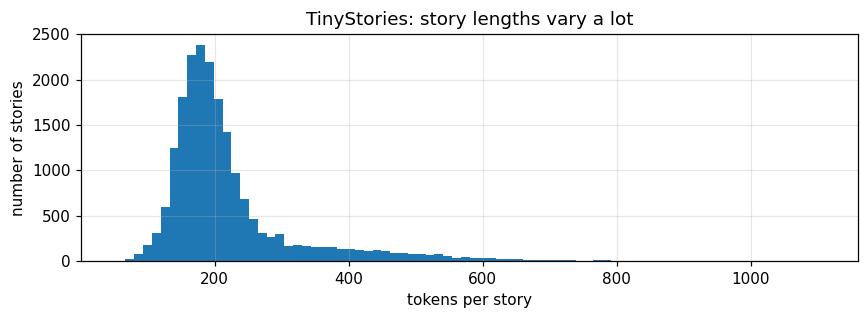

In [8]:
enc = tiktoken.get_encoding("gpt2")
EOT = enc.eot_token                     # 50256, appended to the end of every story

N_STORIES = 20_000

def load_tinystories(n):
    """First n TinyStories training texts.

    Downloads one Parquet shard of the train split in bulk (cached on disk, so re-runs are instant)
    instead of streaming row by row over HTTP, which is slow without an HF token.
    Falls back to streaming if the repository layout ever changes.
    """
    from huggingface_hub import HfApi, hf_hub_download
    import pyarrow.parquet as pq
    repo = "roneneldan/TinyStories"
    shards = sorted(f for f in HfApi().list_repo_files(repo, repo_type="dataset")
                    if f.endswith(".parquet") and "train" in f and "V2" not in f)
    if shards:
        path = hf_hub_download(repo, shards[0], repo_type="dataset")
        return pq.read_table(path, columns=["text"]).column("text").to_pylist()[:n], shards[0]
    stream = load_dataset(repo, split="train", streaming=True)
    return [row["text"] for row in stream.take(n)], "streaming fallback"

t0 = time.time()
texts, source = load_tinystories(N_STORIES)
t_download = time.time() - t0
stories = [ids + [EOT] for ids in enc.encode_ordinary_batch(texts, num_threads=8)]   # multi-threaded tokenizer
train_stories, eval_stories = stories[:19_000], stories[19_000:]
print(f"source                    : {source}")
print(f"download + read           : {t_download:.1f} s     tokenize: {time.time() - t0 - t_download:.1f} s")

lens = sorted(len(s) for s in stories)
pct = lambda q: lens[int(q * (len(lens) - 1))]
print(f"stories loaded            : {len(stories):,}  (train {len(train_stories):,}, held-out {len(eval_stories):,})")
print(f"total tokens              : {sum(lens):,}")
print(f"tokens per story          : min {lens[0]}, 10th pct {pct(.1)}, median {pct(.5)}, "
      f"90th pct {pct(.9)}, max {lens[-1]}")
print(f"longest / shortest story  : {lens[-1] / lens[0]:.1f}x")

sample = stories[0]
print(f"\nfirst story, decoded      : {enc.decode(sample[:45])!r} ...")
print(f"its first 10 token ids    : {sample[:10]}")
print(f"what each id stands for   : {[enc.decode([t]) for t in sample[:10]]}")

plt.figure(figsize=(8, 3))
plt.hist(lens, bins=80, color="tab:blue")
plt.xlabel("tokens per story"); plt.ylabel("number of stories"); plt.title("TinyStories: story lengths vary a lot")
plt.tight_layout(); plt.show()

### From stories to a training batch

A language model is trained to predict token $t+1$ from tokens $0 \dots t$. So the **input** is the story
without its last token and the **target** is the story shifted left by one.

Stories in one batch have different lengths, but a tensor must be rectangular, so shorter stories are
padded at the end. Padded target positions get the label $-100$, which `cross_entropy(ignore_index=-100)`
skips: **padding is never counted in the loss.**

| | position 0 | position 1 |
|---|---|---|
| story A = `[5, 6, 7]`: input / target | 5 → **6** | 6 → **7** |
| story B = `[8, 9]`: input / target | 8 → **9** | pad → *ignored* (−100) |

Three real predictions, one padding slot.

In [9]:
def make_batch(docs, max_len=512):
    """Turn a list of token lists into one right-padded training batch on the GPU.

    Input is each story without its last token; target is each story without its first token,
    so position t learns to predict token t+1. Short stories are padded at the end: the input with
    EOT (never predicted from, so any id works) and the target with -100 (skipped by the loss).

    Example:
        make_batch([[5, 6, 7], [8, 9]])
        x = [[5, 6], [8, 50256]]     (B=2, T=2) inputs
        y = [[6, 7], [9, -100]]      (B=2, T=2) targets: 3 real tokens, 1 padding

    Args:
        docs: list of B token-id lists.
        max_len: stories longer than this are cut, so T <= max_len.
    Returns:
        x, y: (B, T) int64 tensors, T = (longest story in the batch) - 1.
    """
    docs = [d[: max_len + 1] for d in docs]
    T = max(len(d) for d in docs) - 1
    x = torch.full((len(docs), T), EOT, dtype=torch.long)
    y = torch.full((len(docs), T), -100, dtype=torch.long)
    for row, d in enumerate(docs):
        n = len(d) - 1
        x[row, :n] = torch.tensor(d[:-1])
        y[row, :n] = torch.tensor(d[1:])
    return x.to(device), y.to(device)


x, y = make_batch([[5, 6, 7], [8, 9]])
print("inputs  x :", x.tolist(), "   expected [[5, 6], [8, 50256]]")
print("targets y :", y.tolist(), "   expected [[6, 7], [9, -100]]")
print(f"real (non-padding) target tokens: {(y != -100).sum().item()}   expected 3")

inputs  x : [[5, 6], [8, 50256]]    expected [[5, 6], [8, 50256]]
targets y : [[6, 7], [9, -100]]    expected [[6, 7], [9, -100]]
real (non-padding) target tokens: 3   expected 3


---
## Step 1 — Every tensor shape in one training step

One training step is five lines:

```python
logits = model(x)                      # forward:  (B, T) ids -> (B, T, V) scores
loss   = loss_fn(logits, y)            # one number
loss.backward()                        # one gradient per weight
optimizer.step()                       # move every weight
optimizer.zero_grad()                  # wipe gradients before the next step
```

### 1.1 Predict the parameter count before running anything

$$
N \;=\; \underbrace{V D}_{\text{embedding} \,=\, \text{LM head (tied)}}
\;+\; L\Big(\underbrace{3D^2 + D^2}_{\text{attention: } qkv,\ \text{proj}}
\;+\; \underbrace{3 D F}_{\text{SwiGLU: gate, up, down}}
\;+\; \underbrace{2D}_{\text{two RMSNorms}}\Big)
\;+\; \underbrace{D}_{\text{final norm}}
$$

| Part | Formula | Count |
|---|---|---:|
| embedding / head | $50{,}304 \times 384$ | 19,316,736 |
| attention per layer | $4 \times 384^2$ | 589,824 |
| SwiGLU per layer | $3 \times 384 \times 1024$ | 1,179,648 |
| norms per layer | $2 \times 384$ | 768 |
| 6 layers | $6 \times 1{,}770{,}240$ | 10,621,440 |
| final norm | $384$ | 384 |
| **total** | | **29,938,560** |

**64.5%** of the model is the embedding matrix. The lesson pointed to the same thing in V5's
536.9M-weight output head: with a large vocabulary, the head dominates small models.

### 1.2 Predict the loss at initialisation

Cross-entropy for one token is $\mathcal{L} = -\ln p(\text{correct token})$. Weights start small (std 0.02),
so all $V$ logits start close to each other and the softmax is close to uniform, $p \approx 1/V$:

$$\mathcal{L}_{\text{init}} \approx -\ln\frac{1}{V} = \ln 50{,}304 = 10.826$$

A first loss far from 10.8 would mean something is wrong before training even starts (bad initialisation,
labels misaligned, padding counted).

In [10]:
cfg = Config()
model = GPT(cfg).to(device)

def count(module):
    return sum(p.numel() for p in module.parameters())

n_params = count(model)          # the tied matrix is one Parameter, so it is counted once
groups = {
    "embedding / LM head (tied)": model.embed.weight.numel(),
    "attention (all layers)": sum(count(b.attn) for b in model.blocks),
    "SwiGLU MLP (all layers)": sum(count(b.mlp) for b in model.blocks),
    "RMSNorm gains (all)": sum(count(b.norm1) + count(b.norm2) for b in model.blocks) + count(model.norm),
}
print(f"{'part':<30}{'weights':>14}{'share':>9}")
for name, n in groups.items():
    print(f"{name:<30}{n:>14,}{n / n_params:>9.1%}")
print(f"{'total (measured)':<30}{n_params:>14,}")
print(f"{'total (hand prediction)':<30}{29_938_560:>14,}   match: {n_params == 29_938_560}")

part                                 weights    share
embedding / LM head (tied)        19,316,736    64.5%
attention (all layers)             3,538,944    11.8%
SwiGLU MLP (all layers)            7,077,888    23.6%
RMSNorm gains (all)                    4,992     0.0%
total (measured)                  29,938,560
total (hand prediction)           29,938,560   match: True


### 1.3 Forward pass: every intermediate shape

Two real stories ($B = 2$). $T$ is set by the longer story. The model records each intermediate tensor
(see `_rec` in `model.py`), and the table below names every dimension.

In [12]:
B = 2
x, y = make_batch(stories[:B])

trace = []
with torch.autocast(**AMP):
    logits = model(x, trace=trace)

def named(shape, dims):
    """(2, 177, 384) + ("B", "T", "D")  ->  "(B=2, T=177, D=384)"."""
    return "(" + ", ".join(f"{d}={s}" for d, s in zip(dims, shape)) + ")"

print(f"batch: B = {x.shape[0]} stories, T = {x.shape[1]} positions (longest story minus one)\n")
print(f"{'tensor':<20}{'shape with named dimensions':<34}what it holds")
print("-" * 110)
for name, shape, dims, meaning in trace:
    print(f"{name:<20}{named(shape, dims):<34}{meaning}")

batch: B = 2 stories, T = 177 positions (longest story minus one)

tensor              shape with named dimensions       what it holds
--------------------------------------------------------------------------------------------------------------
tokens              (B=2, T=177)                      input token ids
embed               (B=2, T=177, D=384)               one D-dim vector per token (row lookup in the embedding)
block0 qkv          (B=2, T=177, 3D=1152)             query, key and value for every position, side by side
block0 q (per head) (B=2, H=6, T=177, hd=64)          query vectors, split into H heads of width hd
block0 scores       (B=2, H=6, Tq=177, Tk=177)        how much each query position attends to each key position
block0 attn out     (B=2, T=177, D=384)               attention result per position, heads concatenated
block0 mlp hidden   (B=2, T=177, F=1024)              widened per-token features inside the MLP
block0 block out    (B=2, T=177, D=384)              

### 1.4 The loss, unrolled

`loss_sum_and_count` does this in one call. Here every intermediate is printed. The $(B, T, V)$ logits are
flattened so that each of the $B \cdot T$ positions is one classification problem over $V$ classes.

$$
\mathcal{L} \;=\; \frac{1}{\#\{\text{real tokens}\}} \sum_{\text{real positions } i} -\ln \operatorname{softmax}(z_i)_{y_i}
$$

In [13]:
V = logits.shape[-1]
logits_flat = logits.float().view(-1, V)          # (B*T, V)
targets_flat = y.view(-1)                         # (B*T,)
per_token = F.cross_entropy(logits_flat, targets_flat, ignore_index=-100, reduction="none")   # (B*T,)
is_real = targets_flat != -100                    # (B*T,) True for real tokens
loss = per_token.sum() / is_real.sum()            # () a single number

rows = [
    ("logits (flattened)", logits_flat, "every position is one guess over V classes"),
    ("targets (flattened)", targets_flat, "the correct next-token id, or -100 at padding"),
    ("per-token loss", per_token, "-ln p(correct token) per position; exactly 0 at padding"),
    ("real-token mask", is_real, "which positions count"),
    ("loss", loss, "sum of per-token losses / number of real tokens"),
]
print(f"{'tensor':<22}{'shape':<16}{'dtype':<16}meaning")
for name, t, meaning in rows:
    print(f"{name:<22}{str(tuple(t.shape)):<16}{str(t.dtype):<16}{meaning}")

n_real, n_slots = is_real.sum().item(), is_real.numel()
loss_sum, n_tok = loss_sum_and_count(logits, y)
print(f"\npositions: {n_slots} slots = {B} x {x.shape[1]}, of which {n_real} real and {n_slots - n_real} padding")
print(f"loss at initialisation          : {loss.item():.4f}")
print(f"uniform-guess prediction ln(V)  : {math.log(V):.4f}")
print(f"logit spread at init (std)      : {logits.float().std().item():.3f}  (small spread -> close to uniform)")
print(f"same loss via loss_sum_and_count: {(loss_sum / n_tok).item():.4f}")

tensor                shape           dtype           meaning
logits (flattened)    (354, 50304)    torch.float32   every position is one guess over V classes
targets (flattened)   (354,)          torch.int64     the correct next-token id, or -100 at padding
per-token loss        (354,)          torch.float32   -ln p(correct token) per position; exactly 0 at padding
real-token mask       (354,)          torch.bool      which positions count
loss                  ()              torch.float32   sum of per-token losses / number of real tokens

positions: 354 slots = 2 x 177, of which 339 real and 15 padding
loss at initialisation          : 10.8785
uniform-guess prediction ln(V)  : 10.8258
logit spread at init (std)      : 0.393  (small spread -> close to uniform)
same loss via loss_sum_and_count: 10.8785


### 1.5 Backward pass and optimiser step: gradient shapes and memory per weight

`loss.backward()` fills `.grad` for every weight, and each gradient has exactly the shape of its weight:
one number per weight. AdamW then keeps two more numbers per weight (`exp_avg`, a running mean of the
gradient, and `exp_avg_sq`, a running mean of its square).

The lesson's figure is **16 bytes per weight**. We measure it directly below.

In [14]:
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
loss.backward()

shown = ["embed.weight", "blocks.0.norm1.weight", "blocks.0.attn.qkv.weight", "blocks.0.attn.proj.weight",
         "blocks.0.mlp.gate.weight", "blocks.0.mlp.down.weight", "norm.weight"]
params = dict(model.named_parameters())
print(f"{'parameter':<28}{'weight shape':<16}{'grad shape':<16}{'weight dtype':<16}grad dtype")
for name in shown:
    p = params[name]
    print(f"{name:<28}{str(tuple(p.shape)):<16}{str(tuple(p.grad.shape)):<16}{str(p.dtype):<16}{p.grad.dtype}")

optimizer.step()
state = optimizer.state[model.embed.weight]
print("\nAdamW state kept for embed.weight:", {k: (tuple(v.shape), str(v.dtype)) for k, v in state.items()})

weight_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
grad_bytes = sum(p.grad.numel() * p.grad.element_size() for p in model.parameters())
adam_bytes = sum(v.numel() * v.element_size() for s in optimizer.state.values() for v in s.values() if v.dim() > 0)
total = weight_bytes + grad_bytes + adam_bytes
print(f"\n{'memory held for training':<34}{'MiB':>9}{'bytes per weight':>18}")
for name, b in [("weights (fp32)", weight_bytes), ("gradients (fp32)", grad_bytes),
                ("AdamW exp_avg + exp_avg_sq", adam_bytes), ("total", total)]:
    print(f"{name:<34}{b / 2**20:>9.1f}{b / n_params:>18.1f}")
optimizer.zero_grad(set_to_none=True)

parameter                   weight shape    grad shape      weight dtype    grad dtype
embed.weight                (50304, 384)    (50304, 384)    torch.float32   torch.float32
blocks.0.norm1.weight       (384,)          (384,)          torch.float32   torch.float32
blocks.0.attn.qkv.weight    (1152, 384)     (1152, 384)     torch.float32   torch.float32
blocks.0.attn.proj.weight   (384, 384)      (384, 384)      torch.float32   torch.float32
blocks.0.mlp.gate.weight    (1024, 384)     (1024, 384)     torch.float32   torch.float32
blocks.0.mlp.down.weight    (384, 1024)     (384, 1024)     torch.float32   torch.float32
norm.weight                 (384,)          (384,)          torch.float32   torch.float32

AdamW state kept for embed.weight: {'step': ((), 'torch.float32'), 'exp_avg': ((50304, 384), 'torch.float32'), 'exp_avg_sq': ((50304, 384), 'torch.float32')}

memory held for training                MiB  bytes per weight
weights (fp32)                        114.2               4.0

**Reading the result.** The gradients are **fp32**, even though the forward pass ran under bf16 autocast.
Autocast casts the weights to bf16 *for each matmul* but stores them in fp32 (the "master copy"), so the
gradients that flow back into `.grad` are fp32 too. Our split is 4 + 4 + 8 = 16 bytes per weight. The lesson's
split is 2 (bf16 weight) + 2 (bf16 grad) + 4 (fp32 master) + 8 (Adam) = 16. The total is the same, held
differently. Activations come on top of this and are not counted here.

---
## Step 2 — Verify one gradient by hand

`backward()` computes a gradient analytically, with the chain rule. We check it with a measurement that
uses no calculus at all: move one weight a tiny amount and see how much the loss changes.

### 2.1 Why the "nudge" works, and when it fails

Taylor expansion of the loss around the current weight $w$:

$$
\mathcal{L}(w \pm h) \;=\; \mathcal{L}(w) \;\pm\; h\,\mathcal{L}'(w) \;+\; \tfrac{h^2}{2}\mathcal{L}''(w)
\;\pm\; \tfrac{h^3}{6}\mathcal{L}^{(3)}(w) \;+\; \dots
$$

Subtracting the two, the even terms cancel and we get the **central difference**:

$$
\underbrace{\frac{\mathcal{L}(w+h) - \mathcal{L}(w-h)}{2h}}_{\text{"finite-difference gradient"}}
\;=\; \mathcal{L}'(w) \;+\; \underbrace{\tfrac{h^2}{6}\mathcal{L}^{(3)}(w)}_{\text{truncation error}} + \dots
$$

There are two sources of error, pulling $h$ in opposite directions:

| Error | Size | Gets worse when |
|---|---|---|
| **truncation** (the loss is curved, not straight) | $\approx \frac{h^2}{6}\lvert\mathcal{L}^{(3)}\rvert$ | $h$ is **large** |
| **rounding** (each loss is stored with relative precision $\varepsilon$) | $\approx \frac{\varepsilon\,\lvert\mathcal{L}\rvert}{h}$ | $h$ is **small** |

The total is smallest around $h \sim \varepsilon^{1/3}$. With machine epsilon $\varepsilon = 2.2\times10^{-16}$
(float64) that is $h \approx 6\times10^{-6}$; with $\varepsilon = 1.2\times10^{-7}$ (float32) it is
$h \approx 5\times10^{-3}$. This is why the check runs in **float64**: in bf16 ($\varepsilon \approx 8\times10^{-3}$)
it cannot work at all.

### 2.2 The lesson's chain, by hand

$x = 2,\; w_1 = 3,\; w_2 = 4,\; t = 20$. Forward: $h = w_1 x = 6$, $y = w_2 h = 24$, $\mathcal{L} = (y - t)^2 = 16$.

Backward, one local factor per link:

$$
\frac{\partial \mathcal{L}}{\partial y} = 2(y - t) = 8, \qquad
\frac{\partial \mathcal{L}}{\partial w_2} = 8 \cdot h = 48, \qquad
\frac{\partial \mathcal{L}}{\partial h} = 8 \cdot w_2 = 32, \qquad
\frac{\partial \mathcal{L}}{\partial w_1} = 32 \cdot x = 64
$$

In [15]:
x_in, target = 2.0, 20.0
w1 = torch.tensor(3.0, dtype=torch.float64, requires_grad=True)
w2 = torch.tensor(4.0, dtype=torch.float64, requires_grad=True)

def chain_loss(w1, w2):
    """loss = (w2 * (w1 * x) - t)^2 : the lesson's two-weight chain."""
    hidden = w1 * x_in
    out = w2 * hidden
    return (out - target) ** 2

loss_c = chain_loss(w1, w2)
loss_c.backward()

# The four local factors, multiplied by hand, as backpropagation does it.
hidden, out = 3.0 * x_in, 4.0 * 3.0 * x_in
dL_dout = 2 * (out - target)
dL_dw2 = dL_dout * hidden
dL_dhidden = dL_dout * 4.0
dL_dw1 = dL_dhidden * x_in

h = 1e-6
with torch.no_grad():
    fd_w1 = (chain_loss(w1 + h, w2) - chain_loss(w1 - h, w2)) / (2 * h)

print(f"forward : hidden = {hidden}, output = {out}, loss = {loss_c.item()}")
print(f"by hand : dL/dout = {dL_dout}, dL/dw2 = {dL_dw2}, dL/dhidden = {dL_dhidden}, dL/dw1 = {dL_dw1}")
print(f"autograd (backward) : dL/dw1 = {w1.grad.item()}, dL/dw2 = {w2.grad.item()}")
print(f"finite difference   : dL/dw1 = [loss(w1+h) - loss(w1-h)] / 2h with h = {h:g}  ->  {fd_w1.item():.8f}")

forward : hidden = 6.0, output = 24.0, loss = 16.0
by hand : dL/dout = 8.0, dL/dw2 = 48.0, dL/dhidden = 32.0, dL/dw1 = 64.0
autograd (backward) : dL/dw1 = 64.0, dL/dw2 = 48.0
finite difference   : dL/dw1 = [loss(w1+h) - loss(w1-h)] / 2h with h = 1e-06  ->  64.00000001


### 2.3 Six weights inside the real model

The same check on six individual weights spread across the 30M model: the tied embedding, attention,
both MLP matrices and two normalisation gains. A float64 copy of the model is used and the batch is held
fixed, so the only thing changing between the two forward passes is the one nudged weight.

In [16]:
m64 = copy.deepcopy(model).double()           # same weights, stored as 8-byte floats
x_chk, y_chk = make_batch(stories[:4])

def batch_loss(m):
    """Mean per-token loss of model m on the fixed check batch (no autocast: full precision)."""
    s, n = loss_sum_and_count(m(x_chk), y_chk)
    return s / n

def finite_difference(m, weight, idx, h):
    """Central-difference estimate of dLoss/dweight[idx]; restores the weight afterwards.

    Returns (estimate, loss at w + h, loss at w - h).
    """
    with torch.no_grad():
        original = weight[idx].item()
        weight[idx] = original + h; loss_plus = batch_loss(m).item()
        weight[idx] = original - h; loss_minus = batch_loss(m).item()
        weight[idx] = original
    return (loss_plus - loss_minus) / (2 * h), loss_plus, loss_minus

m64.zero_grad(set_to_none=True)
base_loss = batch_loss(m64)
base_loss.backward()
p64 = dict(m64.named_parameters())

to_check = [
    ("embed.weight", (int(x_chk[0, 3]), 7)),     # row of a token that appears in the batch
    ("blocks.0.attn.qkv.weight", (10, 20)),
    ("blocks.0.mlp.gate.weight", (3, 5)),
    ("blocks.3.mlp.down.weight", (5, 100)),
    ("blocks.5.norm2.weight", (17,)),
    ("norm.weight", (3,)),
]
H_CHECK = 1e-5
print(f"loss of the check batch: {base_loss.item():.10f}    nudge size h = {H_CHECK:g}\n")
print(f"{'weight':<36}{'backward() gradient':>22}{'finite-difference grad':>25}{'relative difference':>22}")
check_rows = []
for name, idx in to_check:
    g_bw = p64[name].grad[idx].item()
    g_fd, _, _ = finite_difference(m64, p64[name], idx, H_CHECK)
    rel = abs(g_fd - g_bw) / abs(g_bw)
    check_rows.append((name, idx, g_bw, g_fd, rel))
    print(f"{name + str(list(idx)):<36}{g_bw:>22.10e}{g_fd:>25.10e}{rel:>22.2e}")

grad_check_rel = check_rows[2][4]
print("\nA relative difference of 1e-6 means the two agree to about 6 significant digits.")

loss of the check batch: 10.3269167385    nudge size h = 1e-05

weight                                 backward() gradient   finite-difference grad   relative difference
embed.weight[257, 7]                     -7.0026791230e-03        -7.0026790588e-03              9.16e-09
blocks.0.attn.qkv.weight[10, 20]         -1.1602028415e-04        -1.1602026007e-04              2.08e-07
blocks.0.mlp.gate.weight[3, 5]            2.0211022599e-04         2.0211032847e-04              5.07e-07
blocks.3.mlp.down.weight[5, 100]          1.4886059782e-05         1.4886136768e-05              5.17e-06
blocks.5.norm2.weight[17]                 1.1013105220e-04         1.1013101542e-04              3.34e-07
norm.weight[3]                           -2.2116652840e-04        -2.2116655174e-04              1.06e-07

A relative difference of 1e-6 means the two agree to about 6 significant digits.


### 2.4 When the check fails, and why: sweeping the nudge size

One weight (`blocks.0.mlp.gate.weight[3, 5]`), nudge sizes from $10^{-1}$ down to $10^{-10}$, in float64 and
in float32. Section 2.1 predicts a **U-shape**: errors are large on the right (curvature) and on the left
(rounding), with the bottom near $h \approx 6\times10^{-6}$ for float64 and $h \approx 5\times10^{-3}$ for float32.

reference: backward() gradient in float64 = 2.021102e-04

  nudge h |  float64 estimate  rel. error |  float32 estimate  rel. error
    1e-01 |      2.016869e-04     2.1e-03 |      2.002716e-04     9.1e-03
    1e-02 |      2.021060e-04     2.1e-05 |      1.907349e-04     5.6e-02
    1e-03 |      2.021102e-04     2.1e-07 |      9.536743e-04     3.7e+00
    1e-04 |      2.021102e-04     2.0e-08 |      0.000000e+00     1.0e+00
    1e-05 |      2.021103e-04     5.1e-07 |      4.768372e-02     2.3e+02
    1e-06 |      2.021103e-04     5.1e-07 |      9.536743e-01     4.7e+03
    1e-07 |      2.021139e-04     1.8e-05 |      0.000000e+00     1.0e+00
    1e-08 |      2.022382e-04     6.3e-04 |      0.000000e+00     1.0e+00
    1e-09 |      2.025047e-04     2.0e-03 |      4.768372e+02     2.4e+06
    1e-10 |      1.953993e-04     3.3e-02 |      0.000000e+00     1.0e+00


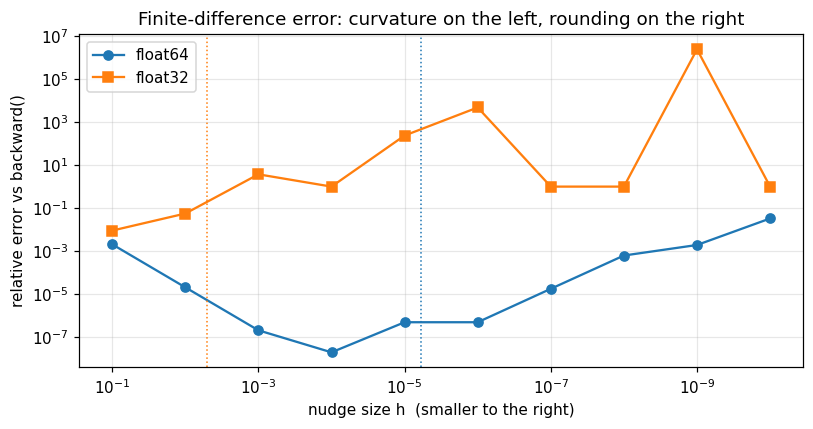

In [17]:
m32 = copy.deepcopy(model).float()
p32 = dict(m32.named_parameters())
name, idx = "blocks.0.mlp.gate.weight", (3, 5)
g_true = p64[name].grad[idx].item()          # backward() in float64 is the reference

h_values = [10.0 ** -k for k in range(1, 11)]
err64, err32 = [], []
print(f"reference: backward() gradient in float64 = {g_true:.6e}\n")
print(f"{'nudge h':>9} | {'float64 estimate':>17}{'rel. error':>12} | {'float32 estimate':>17}{'rel. error':>12}")
for h in h_values:
    e64 = finite_difference(m64, p64[name], idx, h)[0]
    e32 = finite_difference(m32, p32[name], idx, h)[0]
    err64.append(max(abs(e64 - g_true) / abs(g_true), 1e-16))
    err32.append(max(abs(e32 - g_true) / abs(g_true), 1e-16))
    print(f"{h:>9.0e} | {e64:>17.6e}{err64[-1]:>12.1e} | {e32:>17.6e}{err32[-1]:>12.1e}")

plt.figure(figsize=(7.5, 4))
plt.loglog(h_values, err64, "o-", label="float64")
plt.loglog(h_values, err32, "s-", label="float32")
plt.axvline(6e-6, color="tab:blue", ls=":", lw=1); plt.axvline(5e-3, color="tab:orange", ls=":", lw=1)
plt.gca().invert_xaxis()
plt.xlabel("nudge size h  (smaller to the right)"); plt.ylabel("relative error vs backward()")
plt.title("Finite-difference error: curvature on the left, rounding on the right"); plt.legend()
plt.tight_layout(); plt.show()

### 2.5 Does one optimiser step do what the gradient promises?

The previous checks test one weight at a time. This one moves **all 29.9M weights at once**, by one plain
gradient-descent step $\Delta w = -\eta\, g$. To first order the loss should change by

$$
\Delta\mathcal{L}_{\text{predicted}} \;=\; g \cdot \Delta w \;=\; -\eta\,\lVert g\rVert^2 .
$$

If `backward()` were wrong anywhere in the model, predicted and actual would disagree even for small $\eta$.
For large $\eta$ they *should* disagree, because the curvature term $\tfrac{1}{2}\Delta w^\top H\, \Delta w$ takes over.

In [18]:
grads = {n: p.grad.clone() for n, p in m64.named_parameters()}
g_sq = sum((g ** 2).sum().item() for g in grads.values())
loss_before = base_loss.item()
print(f"squared gradient norm ||g||^2 = {g_sq:.6e}    loss before the step = {loss_before:.10f}\n")
print(f"{'step size eta':>14}{'predicted dLoss':>18}{'actual dLoss':>18}{'actual / predicted':>20}")
for eta in [1e0, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    with torch.no_grad():
        for n, p in m64.named_parameters():
            p -= eta * grads[n]
        actual = batch_loss(m64).item() - loss_before
        for n, p in m64.named_parameters():
            p += eta * grads[n]                      # undo the step
    predicted = -eta * g_sq
    print(f"{eta:>14.0e}{predicted:>18.6e}{actual:>18.6e}{actual / predicted:>20.6f}")

del m64, m32, grads
torch.cuda.empty_cache()

squared gradient norm ||g||^2 = 1.224745e+01    loss before the step = 10.3269167385

 step size eta   predicted dLoss      actual dLoss  actual / predicted
         1e+00     -1.224745e+01     -9.420754e-01            0.076920
         1e-01     -1.224745e+00     -5.731982e-01            0.468014
         1e-02     -1.224745e-01     -1.163668e-01            0.950131
         1e-03     -1.224745e-02     -1.219520e-02            0.995734
         1e-04     -1.224745e-03     -1.224233e-03            0.999582
         1e-05     -1.224745e-04     -1.224694e-04            0.999958
         1e-06     -1.224745e-05     -1.224740e-05            0.999996


**Reading the result.** As $\eta$ shrinks, the ratio *actual / predicted* should approach 1.000. That
confirms the gradient is correct for every weight at once, not just the six above. For large $\eta$ the
step overshoots into the curved part of the loss and the ratio drifts away from 1. That drift is expected,
and it is the reason learning rates cannot be made arbitrarily large.

---
## Step 3 — Breaking gradient accumulation on purpose

### 3.1 Why micro-batches hold different numbers of real tokens

In LLM training the loss is an average **over tokens that count**, and many positions in a batch do not count:

| Source of non-counting positions | Where it happens |
|---|---|
| **Padding.** Sequences have different lengths; padding targets are $-100$ and skipped | pretraining with variable-length documents, any padded batching (this notebook) |
| **Prompt masking.** In instruction tuning only the *response* tokens are trained; prompt tokens get $-100$ | SFT / chat fine-tuning: one example may have 20 response tokens, the next 900 |
| **Length bucketing.** Similar-length sequences are batched together to cut padding (`group_by_length`) | makes one micro-batch all-short and the next all-long |
| **Data parallelism.** Each GPU sees a different micro-batch | 8 GPUs, 8 different token counts, all averaged into one step |

So yes: the difference between micro-batches comes from the **number of valid (non-ignored) target tokens**.
Every micro-batch has the same *shape*, but not the same number of tokens that carry loss.

### 3.2 The problem, in symbols

One optimiser step uses $K$ micro-batches. Micro-batch $i$ has $n_i$ real tokens and summed loss
$S_i = \sum_{\text{tokens in } i} \ell_{\text{token}}$. The quantity we *want* is the per-token mean over the whole batch:

$$
\mathcal{L}_{\text{correct}} \;=\; \frac{\sum_{i=1}^{K} S_i}{\sum_{i=1}^{K} n_i}
\qquad\text{every token weighted } \frac{1}{\sum_j n_j}
$$

What a naive loop computes: each micro-batch's own mean, then the mean of those means:

$$
\mathcal{L}_{\text{buggy}} \;=\; \frac{1}{K}\sum_{i=1}^{K} \frac{S_i}{n_i}
\qquad\text{a token in micro-batch } i \text{ weighted } \frac{1}{K\, n_i}
$$

The two are equal only if every $n_i$ is the same. Otherwise **tokens in short micro-batches get a bigger vote**,
and since the gradient is the derivative of this loss, the *gradient* is reweighted too, not just the printed number.

The lesson's example: $n = (4, 4, 2)$, mean losses $(2.0, 2.0, 5.0)$:

$$
\mathcal{L}_{\text{correct}} = \frac{4(2.0) + 4(2.0) + 2(5.0)}{4 + 4 + 2} = 2.6
\qquad
\mathcal{L}_{\text{buggy}} = \frac{2.0 + 2.0 + 5.0}{3} = 3.0
$$

### 3.3 How it hid, and how it was fixed

It hid because in casual tests micro-batches have equal token counts (fixed-length packed sequences, no
masking), and then the two formulas agree exactly. It surfaced in 2024, when users noticed that fine-tuning with
gradient accumulation gave a higher loss than the same batch run in one piece. It was traced to this averaging,
and libraries such as Hugging Face Transformers changed the loss to divide by the total number of items in the
whole accumulated batch.

**The fix, in code:** before the backward passes, count the real tokens of all $K$ micro-batches (cheap: one
comparison on the labels), then divide each micro-batch's *summed* loss by that total:

```python
n_total = sum((y != -100).sum() for _, y in micro_batches)       # whole step's real tokens
for x, y in micro_batches:
    loss_sum, _ = loss_sum_and_count(model(x), y)
    (loss_sum / n_total).backward()                              # correct: each token weighs 1 / n_total
#   (loss_sum / n_i / K).backward()                              # buggy: average of averages
```

With data parallelism, `n_total` must also be summed across GPUs (one all-reduce), for the same reason.

In [19]:
tokens = [4, 4, 2]
mean_losses = [2.0, 2.0, 5.0]
K = len(tokens)
correct = sum(n * l for n, l in zip(tokens, mean_losses)) / sum(tokens)
buggy = sum(mean_losses) / K
print(f"per-token mean (correct)        : {correct:.4f}")
print(f"average of averages (buggy)     : {buggy:.4f}   -> {(buggy - correct) / correct:+.1%} off\n")
print(f"{'micro-batch':<14}{'real tokens':>12}{'weight per token, correct':>28}{'weight per token, buggy':>26}")
for i, n in enumerate(tokens, 1):
    print(f"{i:<14}{n:>12}{f'1/{sum(tokens)} = {1 / sum(tokens):.3f}':>28}{f'1/({K}x{n}) = {1 / (K * n):.3f}':>26}")

per-token mean (correct)        : 2.6000
average of averages (buggy)     : 3.0000   -> +15.4% off

micro-batch    real tokens   weight per token, correct   weight per token, buggy
1                        4                1/10 = 0.100           1/(3x4) = 0.083
2                        4                1/10 = 0.100           1/(3x4) = 0.083
3                        2                1/10 = 0.100           1/(3x2) = 0.167


### 3.4 Setting up realistic micro-batches

Each optimiser step reads $K = 4$ micro-batches of 8 stories. Stories are **bucketed by length** before batching
(sorted, chunked into groups of 8, and the groups shuffled), as `group_by_length` does in common trainers to cut
padding. One micro-batch can then hold about 500 real tokens and the next about 4,000, so the token counts are
unequal for a realistic reason.

In [20]:
MICRO, ACCUM, STEPS, LR, WARMUP = 8, 4, 300, 1e-3, 30

def build_plan(docs, steps, seed=SEED):
    """Length-bucketed micro-batches, grouped into optimiser steps.

    Returns a list of `steps` entries; each entry is a list of ACCUM (x, y) micro-batches.
    Example: plan[0] = [(x, y) with ~ 8 x 60 tokens, (x, y) with ~ 8 x 480 tokens, ...]
    """
    order = sorted(range(len(docs)), key=lambda k: len(docs[k]))
    groups = [order[k:k + MICRO] for k in range(0, len(order) - MICRO + 1, MICRO)]
    random.Random(seed).shuffle(groups)
    mbs = [make_batch([docs[k] for k in g]) for g in groups[: steps * ACCUM]]
    return [mbs[s * ACCUM:(s + 1) * ACCUM] for s in range(steps)]

plan = build_plan(train_stories, STEPS)
probe = make_batch(eval_stories[:16])                                   # fixed batch for a noise-free loss
eval_set = [make_batch(eval_stories[k:k + 16]) for k in range(16, 400, 16)]

print("real target tokens in each of the 4 micro-batches, first 5 steps:")
for s in range(5):
    counts = [(y != -100).sum().item() for _, y in plan[s]]
    print(f"  step {s}: {counts}   largest / smallest = {max(counts) / min(counts):.1f}x")

real target tokens in each of the 4 micro-batches, first 5 steps:
  step 0: [1888, 699, 1704, 3275]   largest / smallest = 4.7x
  step 1: [2957, 1576, 2272, 1624]   largest / smallest = 1.9x
  step 2: [1400, 1184, 2184, 1304]   largest / smallest = 1.8x
  step 3: [1256, 1595, 1824, 1560]   largest / smallest = 1.5x
  step 4: [1760, 1960, 1888, 1536]   largest / smallest = 1.3x


### 3.5 Proof first: correct accumulation equals the full batch, buggy does not

Before training anything, a direct test: compute the gradient of **all 32 stories in one batch**
(the ground truth), then the gradient accumulated over the 4 micro-batches both ways, and compare.
fp32, no autocast, so the comparison is not blurred by bf16 rounding.

Then the same test with 4 micro-batches of **equal** token count (fixed-length chunks, no padding), where the
bug should vanish exactly.

In [21]:
def flat_grad(m):
    """All gradients of model m concatenated into one long vector."""
    return torch.cat([p.grad.reshape(-1) for p in m.parameters()])

def accumulated_grad(m, micro_batches, mode):
    """Gradient after accumulating over micro_batches with mode 'correct' or 'buggy' (fp32, no autocast)."""
    m.zero_grad(set_to_none=True)
    n_total = sum((y != -100).sum() for _, y in micro_batches)
    for x, y in micro_batches:
        s, n = loss_sum_and_count(m(x), y)
        (s / n_total if mode == "correct" else s / n / len(micro_batches)).backward()
    return flat_grad(m)

def full_batch_grad(m, micro_batches):
    """Gradient of the per-token mean loss over all micro-batches stacked into one batch."""
    T = max(x.shape[1] for x, _ in micro_batches)
    pad = lambda t, v: F.pad(t, (0, T - t.shape[1]), value=v)
    x = torch.cat([pad(x, EOT) for x, _ in micro_batches])
    y = torch.cat([pad(y, -100) for _, y in micro_batches])
    m.zero_grad(set_to_none=True)
    s, n = loss_sum_and_count(m(x), y)
    (s / n).backward()
    return flat_grad(m)

def compare(label, micro_batches):
    torch.manual_seed(SEED)
    m = GPT(cfg).to(device)
    g_full = full_batch_grad(m, micro_batches)
    counts = [(y != -100).sum().item() for _, y in micro_batches]
    print(f"{label}   real tokens per micro-batch: {counts}")
    for mode in ["correct", "buggy"]:
        g = accumulated_grad(m, micro_batches, mode)
        rel = ((g - g_full).norm() / g_full.norm()).item()
        cos = F.cosine_similarity(g, g_full, dim=0).item()
        print(f"   {mode:<8} accumulation vs full batch:  relative difference {rel:.2e}   cosine similarity {cos:.6f}")
    del m

def pick_unequal_step(plan, max_T=320, min_ratio=3.0):
    """A step whose micro-batches differ a lot in real tokens, yet short enough to fit as one full batch."""
    for s, mbs in enumerate(plan):
        counts = [(y != -100).sum().item() for _, y in mbs]
        if max(x.shape[1] for x, _ in mbs) <= max_T and max(counts) / min(counts) >= min_ratio:
            return s
    return 0

s_cmp = pick_unequal_step(plan)
compare(f"UNEQUAL token counts (length-bucketed, step {s_cmp})", plan[s_cmp])

flat_tokens = torch.tensor([t for s in train_stories[:200] for t in s], device=device)
chunks = flat_tokens[: 4 * MICRO * 257].view(4, MICRO, 257)
equal_mbs = [(c[:, :-1].contiguous(), c[:, 1:].contiguous()) for c in chunks]
compare("\nEQUAL token counts (packed, no padding)", equal_mbs)
torch.cuda.empty_cache()

UNEQUAL token counts (length-bucketed, step 61)   real tokens per micro-batch: [1944, 1208, 2008, 572]
   correct  accumulation vs full batch:  relative difference 5.30e-07   cosine similarity 1.000000
   buggy    accumulation vs full batch:  relative difference 2.00e-01   cosine similarity 0.982859

EQUAL token counts (packed, no padding)   real tokens per micro-batch: [2048, 2048, 2048, 2048]
   correct  accumulation vs full batch:  relative difference 5.58e-07   cosine similarity 1.000000
   buggy    accumulation vs full batch:  relative difference 5.58e-07   cosine similarity 1.000000


**Reading the result.** With unequal counts, *correct* matches the full-batch gradient to rounding level
(around $10^{-6}$ or smaller), while *buggy* is visibly off in both size and direction (cosine below 1). With
equal counts both match, which is exactly how the bug stayed hidden.

### 3.6 Two training runs, side by side

Two models with **identical starting weights** (same seed), the **same micro-batches in the same order**,
and the same AdamW settings (lr $10^{-3}$, 30 warm-up steps, clip 1.0). The only difference is the one line
inside the accumulation loop. Three things are logged:

1. **training loss of each step, measured correctly per token** for both runs, so the curves are comparable
2. **held-out loss** on 384 unseen stories every 25 steps: the honest measure of which model learned more
3. for the correct run, **the number the buggy formula would have printed** next to the true number. This is the
   *reporting* error: what you would see in your logs if you used the wrong average.

One caveat: AdamW divides each update by a running gradient scale, so the bug's effect on *training* is smaller
than its effect on the *gradient* (3.5). Adam cancels a uniform rescaling of the loss, but it does **not** cancel a
reweighting of which tokens matter, and that reweighting is what the bug does.

In [22]:
@torch.no_grad()
def eval_loss(m, batches):
    """Per-token mean loss of model m over a list of (x, y) batches."""
    total, n_total = 0.0, 0
    for x, y in batches:
        with torch.autocast(**AMP):
            s, n = loss_sum_and_count(m(x), y)
        total += s.item(); n_total += n.item()
    return total / n_total

def train_run(mode, plan, lr=LR, warmup=WARMUP, clip=1.0, lr_at=None, seed=SEED):
    """Train a fresh model over `plan` and log everything Step 3 and Step 4 need.

    Args:
        mode: "correct" (divide summed loss by the step's total real tokens) or
              "buggy"   (divide each micro-batch's mean by the number of micro-batches).
        plan: list of steps, each a list of (x, y) micro-batches (see build_plan).
        clip: max gradient norm; float("inf") disables clipping.
        lr_at: optional function step -> learning rate, replacing linear warm-up + constant.
    Returns:
        (model, log) where log holds one value per step for: true (per-token training loss),
        reported (what the buggy average prints), gnorm (pre-clip gradient norm), probe (loss on
        a fixed held-out batch after the step), and eval/eval_step every 25 steps.
    """
    torch.manual_seed(seed)
    m = GPT(cfg).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1, fused=True)
    log = {k: [] for k in ["true", "reported", "gnorm", "probe", "eval_step", "eval"]}
    for step, micro_batches in enumerate(plan):
        for group in opt.param_groups:
            group["lr"] = lr_at(step) if lr_at else lr * min(1.0, (step + 1) / warmup)

        n_total = sum((y != -100).sum() for _, y in micro_batches)
        step_sum, mb_means = 0.0, []
        for x, y in micro_batches:
            with torch.autocast(**AMP):
                s, n = loss_sum_and_count(m(x), y)
            if mode == "correct":
                (s / n_total).backward()
            else:
                (s / n / len(micro_batches)).backward()
            step_sum += s.item(); mb_means.append(s.item() / n.item())

        grad_norm = torch.nn.utils.clip_grad_norm_(m.parameters(), clip)   # returns the norm BEFORE clipping
        opt.step()
        opt.zero_grad(set_to_none=True)

        log["true"].append(step_sum / n_total.item())
        log["reported"].append(sum(mb_means) / len(mb_means))
        log["gnorm"].append(grad_norm.item())
        log["probe"].append(eval_loss(m, [probe]))
        if step % 25 == 0 or step == len(plan) - 1:
            log["eval_step"].append(step); log["eval"].append(eval_loss(m, eval_set))
    return m, log

t0 = time.time()
model_ok, log_ok = train_run("correct", plan)
model_bad, log_bad = train_run("buggy", plan)
print(f"two training runs of {STEPS} steps each took {time.time() - t0:.0f} s")
del model_bad; torch.cuda.empty_cache()

two training runs of 300 steps each took 117 s


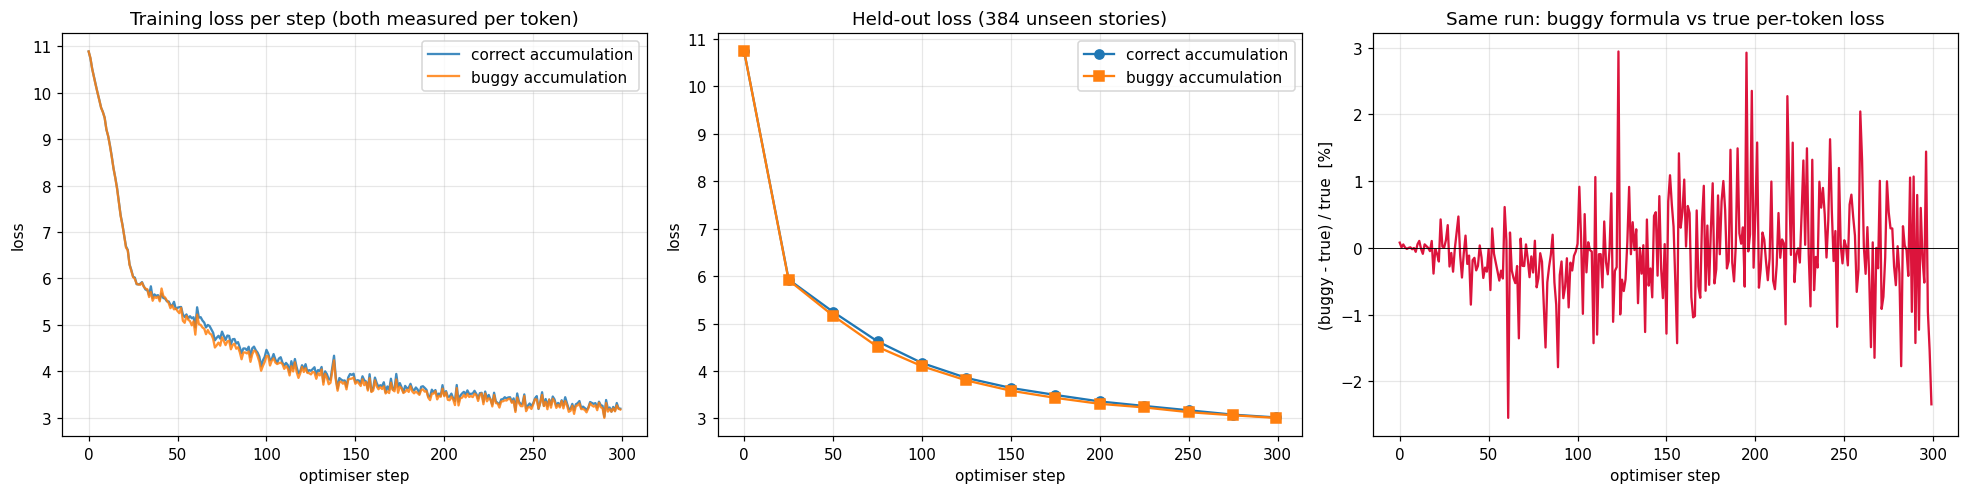

held-out loss at the end     : correct 3.0205   buggy 3.0106   (buggy - correct = -0.0099)
largest held-out gap         : -0.1161 at step 75
reporting error of the buggy formula on the correct run: mean -0.03%, largest +2.94%


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].plot(log_ok["true"], label="correct accumulation", alpha=0.85)
ax[0].plot(log_bad["true"], label="buggy accumulation", alpha=0.85)
ax[0].set(title="Training loss per step (both measured per token)", xlabel="optimiser step", ylabel="loss")
ax[0].legend()

ax[1].plot(log_ok["eval_step"], log_ok["eval"], "o-", label="correct accumulation")
ax[1].plot(log_bad["eval_step"], log_bad["eval"], "s-", label="buggy accumulation")
ax[1].set(title="Held-out loss (384 unseen stories)", xlabel="optimiser step", ylabel="loss")
ax[1].legend()

report_gap = [(r - t) / t * 100 for r, t in zip(log_ok["reported"], log_ok["true"])]
ax[2].plot(report_gap, color="crimson")
ax[2].axhline(0, color="k", lw=0.6)
ax[2].set(title="Same run: buggy formula vs true per-token loss", xlabel="optimiser step",
          ylabel="(buggy - true) / true  [%]")
plt.tight_layout(); plt.savefig("grad_accum_bug.png", dpi=120); plt.show()

eval_gaps = [b - a for a, b in zip(log_ok["eval"], log_bad["eval"])]
print(f"held-out loss at the end     : correct {log_ok['eval'][-1]:.4f}   buggy {log_bad['eval'][-1]:.4f}   "
      f"(buggy - correct = {eval_gaps[-1]:+.4f})")
print(f"largest held-out gap         : {max(eval_gaps, key=abs):+.4f} at step {log_ok['eval_step'][eval_gaps.index(max(eval_gaps, key=abs))]}")
print(f"reporting error of the buggy formula on the correct run: mean {statistics.mean(report_gap):+.2f}%, "
      f"largest {max(report_gap, key=abs):+.2f}%")

> **Observations**
>
> - **The gradient is clearly wrong under the bug.** Against the full-batch gradient, buggy accumulation is 20% off
>   (cosine 0.983), while correct accumulation agrees to $5\times10^{-7}$. With equal token counts both agree to
>   $5.6\times10^{-7}$. That is exactly how the bug stayed hidden.
> - **The printed loss looks fine.** The buggy formula is off by up to ±3% on single steps (right panel), but averages out
>   to −0.03%. Nobody would spot it on a loss curve.
> - **The training outcome barely differs, and not in the expected direction.** Held-out loss at step 299: correct 3.0205,
>   buggy 3.0106. The buggy run was slightly ahead for most of training (largest gap −0.116 at step 75). AdamW normalises
>   update sizes, which damps the effect of reweighting, and with one seed and 300 steps a 0.01 difference is within
>   run-to-run noise. This run cannot show the bug making training worse. What it shows is that the optimiser was fed a
>   different objective than intended, and no curve said so.

---
## Step 4 — The grad norm as an early warning

### 4.1 What is logged

The **gradient norm** is the length of the whole gradient, treating all 29.9M partial derivatives as one vector:

$$
\lVert g \rVert_2 \;=\; \sqrt{\sum_{k=1}^{N} g_k^2}
$$

**Gradient clipping** caps that length at $c$ (here $c = 1$) without changing the direction:

$$
g \;\leftarrow\; g \cdot \min\!\left(1,\; \frac{c}{\lVert g \rVert_2}\right)
\qquad\text{e.g. } \lVert g\rVert = 8.4,\ c = 1 \;\Rightarrow\; \text{every } g_k \text{ multiplied by } 0.119
$$

`clip_grad_norm_` returns the norm **before** clipping. That is the number we log at every step.

### 4.2 Is it true that the grad norm moves before the loss?

> *"In many LLM training instability scenarios, the gradient norm starts increasing or spikes before the
> training loss shows a noticeable spike. However, this is not a universal rule. Sometimes both increase
> together, and sometimes the loss spikes first."*

**Yes, that is an accurate statement.** Here is why the norm often leads, with small numbers. Near a
minimum the loss is roughly a bowl, $\mathcal{L} \approx \mathcal{L}^* + \tfrac{1}{2}\lambda\,\delta^2$, where $\delta$
is the distance from the bottom and $\lambda$ the curvature. Then

$$
\lVert g \rVert = \lambda\,\delta \quad(\text{linear in } \delta), \qquad
\mathcal{L} - \mathcal{L}^* = \tfrac{1}{2}\lambda\,\delta^2 \quad(\text{quadratic in } \delta).
$$

When the learning rate is too large for the curvature, each step overshoots and $\delta$ grows. Take $\lambda = 100$ on a
loss of about 2.0:

| $\delta$ | grad norm $\lambda\delta$ | loss excess $\tfrac12\lambda\delta^2$ | visible? |
|---|---:|---:|---|
| 0.001 | 0.1 | 0.00005 | — |
| 0.002 | 0.2 (**doubled**) | 0.0002 | norm yes, loss no (0.01% of 2.0) |
| 0.004 | 0.4 (**4x**) | 0.0008 | norm yes, loss no |
| 0.032 | 3.2 | 0.051 | both |

The norm doubles at every step from the start, while the loss stays buried in batch-to-batch noise until $\delta$ is
large. In addition, the loss at step $t$ is measured before step $t$'s update, while a large gradient at step $t$ only
harms the loss through the update it causes, so it shows one step later.

**When it does not lead:**
- **A bad batch** (corrupted or out-of-distribution data). Loss and gradient are computed on the same batch, so
  both jump at the same step. Experiment 4.5 below shows this.
- **Data or distribution shift.** The loss rises because the data got harder, not because the optimiser is unstable;
  the norm may not move first.
- **Optimiser effects.** Adam divides by a running gradient scale, so a gradually rising norm can be absorbed for a
  while; and once clipping is active the norm keeps rising while the update size is capped.

### 4.3 The natural run: searching for a step where the norm moved first

The search runs over every step of the correct run from Step 3. The loss used is the loss on a **fixed held-out probe
batch**, measured after each step, so that changes reflect the model and not which stories happened to be drawn.

A candidate step must satisfy all three conditions:
1. the grad norm's change is unusual: $|z| > 2$, where $z$ is the change divided by its typical size;
2. the probe loss barely moves that step: $|z| < 1$;
3. the probe loss then makes a move at least twice as big within the next 5 steps.

Each change is measured against its local trend (a rolling median), because the loss falls steadily anyway and
that steady fall is not a signal.

In [43]:
def lead_candidates(log, look_ahead=5, skip=20):
    """Steps where the grad norm moved unusually while the probe loss did not, but did shortly after.

    Returns a list of (z_norm, step, norm_before, norm_after, loss_change_now, loss_change_later),
    strongest grad-norm move first.
    """
    def detrend(d):
        return [d[k] - statistics.median(d[max(0, k - 10):k + 11]) for k in range(len(d))]
    log_norm, probe_loss = [math.log(v) for v in log["gnorm"]], log["probe"]
    d_norm = detrend([log_norm[k] - log_norm[k - 1] for k in range(1, len(log_norm))])
    d_loss = detrend([probe_loss[k] - probe_loss[k - 1] for k in range(1, len(probe_loss))])
    s_norm, s_loss = statistics.pstdev(d_norm[skip:]), statistics.pstdev(d_loss[skip:])
    found = []
    for k in range(skip, len(d_norm) - look_ahead):     # skip warm-up, where everything moves at once
        z_norm, z_loss = d_norm[k] / s_norm, d_loss[k] / s_loss
        later = max(d_loss[k + 1:k + 1 + look_ahead], key=abs)
        if abs(z_norm) > 2 and abs(z_loss) < 1 and abs(later) > 2 * abs(d_loss[k]):
            found.append((abs(z_norm), k + 1, log["gnorm"][k], log["gnorm"][k + 1], d_loss[k], later))
    return sorted(found, reverse=True)

candidates = lead_candidates(log_ok)
print(f"{len(candidates)} candidate steps found in the natural run (strongest first):\n")
print(f"{'step':>5}{'grad norm before -> after':>28}{'z of norm change':>18}"
      f"{'probe-loss change that step':>30}{'largest change in next 5 steps':>33}")
for z, s, g0, g1, now, later in candidates[:6]:
    print(f"{s:>5}{f'{g0:.3f} -> {g1:.3f}':>28}{z:>18.1f}{now:>+30.4f}{later:>+33.4f}")
natural_step = candidates[0][1] if candidates else None

8 candidate steps found in the natural run (strongest first):

 step   grad norm before -> after  z of norm change   probe-loss change that step   largest change in next 5 steps
   44              1.883 -> 0.706               4.2                       +0.0177                          -0.0931
   49              2.682 -> 1.094               3.8                       +0.0059                          +0.0581
   43              0.850 -> 1.883               2.7                       -0.0164                          -0.0931
  100              0.676 -> 1.352               2.5                       -0.0119                          -0.0290
   45              0.706 -> 1.426               2.4                       +0.0126                          -0.0931
   57              0.900 -> 1.607               2.3                       +0.0178                          +0.0439


### 4.4 An induced instability: learning rate raised 30x

A natural run on clean data is mostly calm, so an instability is also produced on purpose: from step 150 the learning
rate is multiplied by 30 for 20 steps, with clipping **off** so nothing hides the effect. This is deliberate, and it
is labelled as such in the plot.

Each trace gets an alarm line set against its own recent history (the median of the 30 steps before step 150):
- grad norm alarm: above **3x** its median
- loss alarm: probe loss above its median by **5%**

The question is which alarm goes off first.

In [44]:
SPIKE_AT, SPIKE_LEN, SPIKE_X = 150, 20, 30

def spiked_lr(step):
    """Normal warm-up schedule, but 30x larger for steps 150-169."""
    base = LR * min(1.0, (step + 1) / WARMUP)
    return base * SPIKE_X if SPIKE_AT <= step < SPIKE_AT + SPIKE_LEN else base

def first_alarm(series, start, factor, window=30):
    """First step >= start where series exceeds factor x its median over the `window` steps before start."""
    reference = statistics.median(series[start - window:start])
    for k in range(start, len(series)):
        if not series[k] <= factor * reference:      # also fires on NaN, i.e. a run that blew up
            return k, reference
    return None, reference

_, log_spike = train_run("correct", plan[:250], clip=float("inf"), lr_at=spiked_lr)
norm_alarm, norm_ref = first_alarm(log_spike["gnorm"], SPIKE_AT, 3.0)
loss_alarm, loss_ref = first_alarm(log_spike["probe"], SPIKE_AT, 1.05)

print(f"learning rate x{SPIKE_X} from step {SPIKE_AT} to {SPIKE_AT + SPIKE_LEN - 1}, clipping off\n")
print(f"grad norm : median before = {norm_ref:.3f}, first above 3x at step {norm_alarm}")
print(f"probe loss: median before = {loss_ref:.3f}, first above +5% at step {loss_alarm}")
if norm_alarm is not None and loss_alarm is not None:
    lead = loss_alarm - norm_alarm
    if lead == 0:
        print("\n-> both alarms went off at the same step")
    else:
        print(f"\n-> the grad norm raised its alarm {abs(lead)} step(s) {'BEFORE' if lead > 0 else 'AFTER'} the loss")
print("\nsteps around the spike:")
print(f"{'step':>5}{'learning rate':>15}{'grad norm':>12}{'probe loss':>12}")
for k in range(SPIKE_AT - 2, SPIKE_AT + 10):
    print(f"{k:>5}{spiked_lr(k):>15.2e}{log_spike['gnorm'][k]:>12.3f}{log_spike['probe'][k]:>12.4f}")

learning rate x30 from step 150 to 169, clipping off

grad norm : median before = 0.728, first above 3x at step 151
probe loss: median before = 4.133, first above +5% at step 150

-> the grad norm raised its alarm 1 step(s) AFTER the loss

steps around the spike:
 step  learning rate   grad norm  probe loss
  148       1.00e-03       0.696      4.0430
  149       1.00e-03       0.726      4.0346
  150       3.00e-02       0.811      7.9478
  151       3.00e-02       7.391      7.7155
  152       3.00e-02       5.339      9.6298
  153       3.00e-02       7.865      8.5247
  154       3.00e-02       4.800      9.0379
  155       3.00e-02       3.068      9.6346
  156       3.00e-02       6.965      9.2404
  157       3.00e-02       2.922      9.4843
  158       3.00e-02       6.133      9.5714
  159       3.00e-02       6.154      9.2861


### 4.5 A counter-example: one bad batch

At step 120 the four real micro-batches are replaced by **random token ids**, a stand-in for a corrupted data shard.
This is the case from 4.2 where the norm should *not* lead: the training loss and the gradient both come from the same
bad batch, so both should jump at the same step. It runs twice, with clipping on and off, to see what clipping changes.

In [45]:
BAD_AT, BAD_RUN = 120, 200
noise = torch.randint(0, 50257, (ACCUM, MICRO, 513), device=device)
bad_step = [(r[:, :-1].contiguous(), r[:, 1:].contiguous()) for r in noise]
plan_bad = list(plan[:BAD_RUN]); plan_bad[BAD_AT] = bad_step

_, log_bad_clip = train_run("correct", plan_bad, clip=1.0)
_, log_bad_noclip = train_run("correct", plan_bad, clip=float("inf"))

print(f"random-token batch injected at step {BAD_AT}")
print("train loss = loss on that step's own batch;  probe loss = loss on 16 fixed held-out stories after the step\n")
print(f"{'':>5} | {'------------ clip 1.0 ------------':^36} | {'------------ no clip -------------':^36}")
print(f"{'step':>5} | {'train loss':>11}{'grad norm':>11}{'probe loss':>12}   | {'train loss':>11}{'grad norm':>11}{'probe loss':>12}")
for k in range(BAD_AT - 2, BAD_AT + 6):
    a, b = log_bad_clip, log_bad_noclip
    print(f"{k:>5} | {a['true'][k]:>11.3f}{a['gnorm'][k]:>11.3f}{a['probe'][k]:>12.4f}   | "
          f"{b['true'][k]:>11.3f}{b['gnorm'][k]:>11.3f}{b['probe'][k]:>12.4f}")

random-token batch injected at step 120
train loss = loss on that step's own batch;  probe loss = loss on 16 fixed held-out stories after the step

      |  ------------ clip 1.0 ------------  |  ------------ no clip ------------- 
 step |  train loss  grad norm  probe loss   |  train loss  grad norm  probe loss
  118 |       3.951      0.727      4.2363   |       4.010      0.643      4.3043
  119 |       4.037      0.882      4.2340   |       4.101      0.853      4.2819
  120 |      17.429     26.424      4.2753   |      15.502     20.655      4.3746
  121 |       4.149      1.573      4.2538   |       4.248      1.593      4.4239
  122 |       4.209      0.955      4.2271   |       4.357      1.634      4.3936
  123 |       4.041      0.768      4.2600   |       4.161      1.057      4.4157
  124 |       4.099      1.003      4.2275   |       4.212      1.142      4.3919
  125 |       4.054      0.721      4.2254   |       4.236      1.288      4.3377


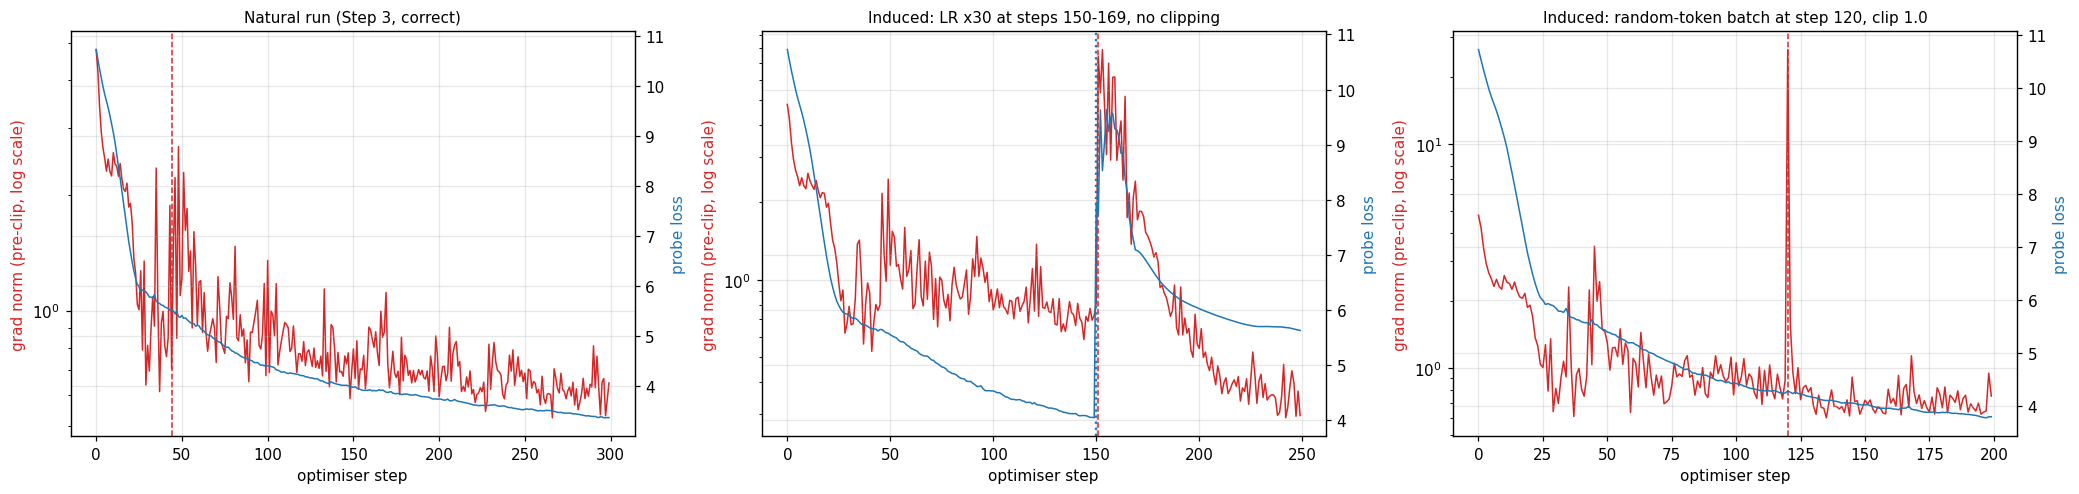

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
panels = [
    (axes[0], log_ok, "Natural run (Step 3, correct)", natural_step, None),
    (axes[1], log_spike, f"Induced: LR x{SPIKE_X} at steps {SPIKE_AT}-{SPIKE_AT + SPIKE_LEN - 1}, no clipping",
     norm_alarm, loss_alarm),
    (axes[2], log_bad_clip, f"Induced: random-token batch at step {BAD_AT}, clip 1.0", BAD_AT, None),
]
for ax, log, title, mark_norm, mark_loss in panels:
    ax.plot(log["gnorm"], color="tab:red", lw=1)
    ax.set_yscale("log"); ax.set_xlabel("optimiser step"); ax.set_ylabel("grad norm (pre-clip, log scale)", color="tab:red")
    twin = ax.twinx()
    twin.plot(log["probe"], color="tab:blue", lw=1); twin.set_ylabel("probe loss", color="tab:blue")
    if mark_norm is not None:
        ax.axvline(mark_norm, color="tab:red", ls="--", lw=1)
    if mark_loss is not None:
        ax.axvline(mark_loss, color="tab:blue", ls=":", lw=1.5)
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig("grad_norm_vs_loss.png", dpi=120); plt.show()

> **Observations**
>
> - **Natural run: the grad norm moved first at step 44.** The norm fell 1.883 → 0.706 (z = 4.2) while the probe loss moved
>   only +0.018; within the next 5 steps the probe loss fell 0.093. Steps 43–49 are the end of the fast initial descent,
>   where the norm swings 0.85 → 1.88 → 0.71 → 1.43 before the loss settles.
> - **Learning rate ×30: no lead.** The loss alarm went off at step 150 (4.03 → 7.95) and the norm alarm at step 151
>   (0.81 → 7.39). A sudden jump gives nothing to warn about in advance. Also, the logging is offset by one step: the grad
>   norm at step $t$ is computed *before* step $t$'s update, the probe loss *after* it. Aligned on the same weights, both
>   moved together. A gradual instability, as in 4.2, is the case where the norm leads. The damage was lasting: 80 steps after the spike ended, the probe loss was still about 5.6, against 4.0 before it.
> - **Bad batch: no lead, as predicted.** Training loss 17.4 and grad norm 26.4 jumped at the same step (15.5 and 20.7 in the no-clip run), because both come
>   from the same batch.
> - **Clipping limited the damage.** With clipping the probe loss rose by 0.041 and was back below its old level 2 steps
>   later; without clipping it rose by 0.14 (4.28 → 4.42) and was still above its old level 5 steps later. The no-clip damage is bounded too, because
>   AdamW divides every update by a running gradient scale, so one huge gradient cannot cause one huge step.

---
## Step 5 — MFU: how much of the GPU are we actually using?

### 5.1 What a FLOP is, and what one matmul costs

A **FLOP** is one floating-point operation: a single multiply or a single add. Almost all the work in a transformer is
matrix multiplication. Multiplying an $(m \times k)$ matrix by a $(k \times n)$ matrix produces $m \cdot n$ outputs, each
a dot product of length $k$ ($k$ multiplies and $k$ adds):

$$
\text{FLOPs}(m \times k \cdot k \times n) \;=\; 2\,m\,k\,n
$$

Tiny check: $(2 \times 3) \cdot (3 \times 4)$ gives 8 outputs, each with 3 multiplies and 3 adds, so $8 \times 6 = 48 = 2 \cdot 2 \cdot 3 \cdot 4$.

### 5.2 FLOPs per token for a whole training step: the $6N$ rule

Every weight $w$ in a linear layer is used once per token in the forward pass: one multiply ($w \cdot x$) and one add
(into the sum), so **2 FLOPs**. The backward pass needs two products per weight: the gradient for the *input*
($\partial \mathcal{L}/\partial x = w \cdot \delta$) to keep backpropagating, and the gradient for the *weight*
($\partial \mathcal{L}/\partial w = x \cdot \delta$), so **4 FLOPs**. In total:

$$
\text{FLOPs per token} \;\approx\; \underbrace{2N}_{\text{forward}} + \underbrace{4N}_{\text{backward}} \;=\; 6N
\;\;+\;\; \underbrace{12\, L\, D\, T}_{\text{attention scores } QK^\top \text{ and } AV}
$$

The attention term covers the two matmuls that involve no weights (scores and weighted values), which grow with
sequence length $T$. For our model at $T = 512$:

$$
6N = 6 \times 29.94\text{M} = 179.6\ \text{MFLOP}, \qquad 12 \cdot 6 \cdot 384 \cdot 512 = 14.2\ \text{MFLOP},
\qquad \text{total} \approx 193.8\ \text{MFLOP per token}.
$$

### 5.3 MFU

$$
\text{MFU} \;=\; \frac{\text{FLOPs per token} \times \text{tokens processed per second}}{\text{peak FLOP/s of the hardware}}
$$

- **Numerator**: the useful work we got done, measured by timing real training steps.
- **Denominator**: what the GPU could do at best. The **L4 is rated at 121 TFLOP/s in dense bf16** (the 242 often
  quoted assumes 2:4 structured sparsity, which ordinary training does not use).
- **"Model" FLOPs** count only the work the model mathematically needs. Wasted work, such as computing padding positions
  or recomputing activations for checkpointing, is not counted. That is the difference from *hardware* FLOPs
  utilisation (HFU).

Hand example: at 100,000 tokens/s we would get $100{,}000 \times 193.8\text{M} = 19.4$ TFLOP/s, so
$\text{MFU} = 19.4 / 121 = 16\%$. Healthy large-scale runs reach 35-50%.

### 5.4 How it is measured here

A GPU runs **asynchronously**: Python queues work and moves on before the GPU has finished. Timing without waiting would
measure how fast Python *queues* work, so every measurement calls `torch.cuda.synchronize()` before starting and before
stopping the clock. A few warm-up steps run first, so one-time costs (memory allocation, kernel selection, compilation)
are excluded.

The experiments, in order:
1. **What can this GPU really do?** Square bf16 matmuls of growing size, versus the 121 spec.
2. **Our model's own matmuls.** Their shapes are tall and thin ($k = 384$), and a roofline view explains why that is slow.
3. **Where the time goes.** The PyTorch profiler on one training step.
4. **MFU for four loop configurations**, each one removing one source of waste.

In [27]:
PEAK_BF16 = 121e12          # NVIDIA L4 datasheet, dense bf16 tensor-core peak (242 is with 2:4 sparsity)
L4_BANDWIDTH = 300e9        # bytes/s of GPU memory bandwidth (datasheet)

def time_cuda(fn, reps=20, warmup=5):
    """Seconds per call of fn(), measured with synchronisation so GPU work is actually finished."""
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps

def matmul_tflops(m, k, n, dtype=torch.bfloat16):
    """Achieved TFLOP/s for one (m x k) @ (k x n) matmul."""
    a = torch.randn(m, k, device=device, dtype=dtype)
    b = torch.randn(k, n, device=device, dtype=dtype)
    return 2 * m * k * n / time_cuda(lambda: a @ b) / 1e12

print("1) square bf16 matmuls (n x n) @ (n x n):")
print(f"{'n':>7}{'TFLOP/s achieved':>18}{'% of 121 peak':>15}")
square = {}
for n in [256, 512, 1024, 2048, 4096, 8192]:
    square[n] = matmul_tflops(n, n, n)
    print(f"{n:>7}{square[n]:>18.1f}{square[n] / 121:>15.0%}")
best_matmul = max(square.values())
fp32_4096 = matmul_tflops(4096, 4096, 4096, torch.float32)
print(f"\nsame 4096 matmul in plain fp32: {fp32_4096:.1f} TFLOP/s "
      f"({square[4096] / fp32_4096:.1f}x slower than bf16: this is why we train with bf16 matmuls)")

1) square bf16 matmuls (n x n) @ (n x n):
      n  TFLOP/s achieved  % of 121 peak
    256               1.6             1%
    512              14.3            12%
   1024              49.1            41%
   2048              69.2            57%
   4096              58.5            48%
   8192              54.7            45%

same 4096 matmul in plain fp32: 11.5 TFLOP/s (5.1x slower than bf16: this is why we train with bf16 matmuls)


**Roofline view.** A matmul must read its inputs from memory and write its output. Its **arithmetic intensity** is the
number of FLOPs it does per byte moved:

$$
I \;=\; \frac{2mkn}{\text{bytes}\big(mk + kn + mn\big)} \qquad (\text{2 bytes per bf16 number})
$$

The GPU can sustain at most $\min\!\big(\text{peak},\; I \times \text{bandwidth}\big)$. For the L4 the crossover is
$121\text{ T} / 300\text{ G} \approx 400$ FLOPs per byte. Below that a matmul is **memory-bound**: the tensor cores
wait for data.

Our model's matmuls for 8,192 tokens (16 sequences of 512), with $D = 384$, are tall and thin:

In [28]:
tokens_per_step = 16 * 512
model_matmuls = [
    ("attention qkv", tokens_per_step, 384, 1152),
    ("attention proj", tokens_per_step, 384, 384),
    ("MLP gate / up", tokens_per_step, 384, 1024),
    ("MLP down", tokens_per_step, 1024, 384),
    ("LM head", tokens_per_step, 384, 50304),
]
print(f"{'matmul':<16}{'shape (m x k) @ (k x n)':<28}{'FLOPs/byte':>11}{'roofline cap':>14}{'achieved':>11}{'of peak':>9}")
for name, m_, k_, n_ in model_matmuls:
    intensity = 2 * m_ * k_ * n_ / (2 * (m_ * k_ + k_ * n_ + m_ * n_))
    cap = min(PEAK_BF16, intensity * L4_BANDWIDTH) / 1e12
    got = matmul_tflops(m_, k_, n_)
    print(f"{name:<16}{f'({m_} x {k_}) @ ({k_} x {n_})':<28}{intensity:>11.0f}{cap:>11.1f} TF{got:>8.1f} TF{got / 121:>9.0%}")

matmul          shape (m x k) @ (k x n)      FLOPs/byte  roofline cap   achieved  of peak
attention qkv   (8192 x 384) @ (384 x 1152)         278       83.5 TF    60.8 TF      50%
attention proj  (8192 x 384) @ (384 x 384)          188       56.3 TF    57.2 TF      47%
MLP gate / up   (8192 x 384) @ (384 x 1024)         270       81.0 TF    61.2 TF      51%
MLP down        (8192 x 1024) @ (1024 x 384)        270       81.0 TF    60.4 TF      50%
LM head         (8192 x 384) @ (384 x 50304)        364      109.2 TF    34.0 TF      28%


### 5.5 Where the time goes in one training step

The profiler records every GPU kernel in a training step (16 x 512 tokens, eager mode) and ranks them by total GPU time.
This shows which operations the time actually goes to.

In [29]:
from torch.profiler import ProfilerActivity, profile

flat_train = torch.tensor([t for s in train_stories[:6000] for t in s], device=device)

def packed_batch(bsz, T=512):
    """bsz random windows of T+1 consecutive tokens from the concatenated stories: no padding at all."""
    starts = torch.randint(0, len(flat_train) - T - 1, (bsz,)).tolist()
    x = torch.stack([flat_train[s:s + T] for s in starts])
    y = torch.stack([flat_train[s + 1:s + T + 1] for s in starts])
    return x, y

def make_train_step(m, opt):
    """One full training step on one batch: forward, loss, backward, clip, AdamW update, zero_grad."""
    def step(x, y):
        with torch.autocast(**AMP):
            s, n = loss_sum_and_count(m(x), y)
        (s / n).backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
    return step

def fresh_model(compiled=False):
    torch.manual_seed(SEED)
    m = GPT(cfg).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, fused=True)
    return (torch.compile(m) if compiled else m), opt

m_prof, opt_prof = fresh_model()
step_prof = make_train_step(m_prof, opt_prof)
xb, yb = packed_batch(16)
for _ in range(3):
    step_prof(xb, yb)
torch.cuda.synchronize()
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
    for _ in range(3):
        step_prof(xb, yb)
    torch.cuda.synchronize()
for key in ["cuda_time_total", "device_time_total"]:
    try:
        print(prof.key_averages().table(sort_by=key, row_limit=12, max_name_column_width=45))
        break
    except Exception:
        continue
del m_prof, opt_prof; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


---------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                         Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
---------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                  aten::copy_         1.20%       5.482ms         9.14%      41.656ms      69.426us      78.712ms        21.53%      78.738ms     131.230us           600  
                                     aten::to         0.18%     805.125us         7.83%      35.698ms      47.408us       0.000us         0.00%      71.838ms      95.403us           753  
                               aten::_to_copy         0.56%

### 5.6 MFU of the training loop, four configurations

Each configuration removes one source of waste from the previous one:

| # | Configuration | What changes |
|---|---|---|
| 1 | Step 3's loop as written: length-bucketed micro-batches of 8 stories, eager PyTorch | baseline. Small batches (1,000-4,000 tokens); any padding is computed but not counted |
| 2 | Packed sequences, 16 x 512, eager | no padding; every position is a real token; bigger matmuls |
| 3 | Packed 16 x 512, `torch.compile` | compiler fuses small elementwise ops (RMSNorm, SiLU, RoPE) into fewer kernels |
| 4 | Packed 32 x 512, `torch.compile` | twice the tokens per step: larger matmuls, launch overhead spread thinner |

Only **real** target tokens are counted, so padding counts as waste, which is the honest choice.

In [30]:
def flops_per_token(T):
    """Model FLOPs per token for one training step at sequence length T (6N + attention)."""
    return 6 * n_params + 12 * cfg.n_layer * cfg.d_model * T

def measure_mfu(step_fn, batches, reps=20, warmup=5):
    """Run step_fn over batches; return (real tokens/s, model TFLOP/s, MFU)."""
    for k in range(warmup):
        step_fn(*batches[k % len(batches)])
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    flops = tokens = 0
    for k in range(reps):
        x, y = batches[k % len(batches)]
        step_fn(x, y)
        real = (y != -100).sum().item()
        tokens += real
        flops += real * flops_per_token(x.shape[1])
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return tokens / dt, flops / dt / 1e12, flops / dt / PEAK_BF16

mfu_rows = []
padded_mbs = [mb for step in plan[:10] for mb in step]
m_, o_ = fresh_model()
mfu_rows.append(("1. padded micro-batches of 8, eager", *measure_mfu(make_train_step(m_, o_), padded_mbs)))
packed16 = [packed_batch(16) for _ in range(8)]
m_, o_ = fresh_model()
mfu_rows.append(("2. packed 16 x 512, eager", *measure_mfu(make_train_step(m_, o_), packed16)))
try:
    m_, o_ = fresh_model(compiled=True)
    mfu_rows.append(("3. packed 16 x 512, compiled", *measure_mfu(make_train_step(m_, o_), packed16, warmup=8)))
    packed32 = [packed_batch(32) for _ in range(8)]
    m_, o_ = fresh_model(compiled=True)
    mfu_rows.append(("4. packed 32 x 512, compiled", *measure_mfu(make_train_step(m_, o_), packed32, warmup=8)))
except Exception as e:
    print(f"torch.compile failed on this runtime: {type(e).__name__}: {str(e)[:200]}")
del m_, o_; torch.cuda.empty_cache()

pad_fraction = 1 - sum((y != -100).sum().item() for _, y in padded_mbs) / sum(y.numel() for _, y in padded_mbs)
print(f"padding in configuration 1: {pad_fraction:.1%} of all positions are padding (computed, not counted)\n")
print(f"{'configuration':<38}{'real tokens/s':>15}{'model TFLOP/s':>15}{'MFU':>8}")
for name, tps, tflops, mfu in mfu_rows:
    print(f"{name:<38}{tps:>15,.0f}{tflops:>15.1f}{mfu:>8.1%}")
print(f"\nfor comparison: the best square matmul reached {best_matmul:.1f} TFLOP/s = {best_matmul / 121:.0%} of peak")

W1031 09:08:54.179000 1314 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


padding in configuration 1: 0.0% of all positions are padding (computed, not counted)

configuration                           real tokens/s  model TFLOP/s     MFU
1. padded micro-batches of 8, eager            42,622            7.9    6.6%
2. packed 16 x 512, eager                      65,226           12.6   10.4%
3. packed 16 x 512, compiled                   75,011           14.5   12.0%
4. packed 32 x 512, compiled                   74,978           14.5   12.0%

for comparison: the best square matmul reached 69.2 TFLOP/s = 57% of peak


> **Observations**
>
> - **MFU: 6.6% → 10.4% → 12.0%.** Larger batches gave the largest gain, then `torch.compile` gave +15%. Doubling the batch
>   again gave nothing.
> - **This L4's real ceiling is about 57% of its spec.** The best square bf16 matmul reached 69.2 TFLOP/s, not 121.
> - **Our matmuls are thin.** With $D = 384$ they reached 57–61 TFLOP/s in isolation, and the LM head only 34.
> - **The vocabulary dominates the step.** In the profiler, dtype copies (`aten::copy_`, including the fp32 upcast of the
>   8192 × 50304 logits) take 21.5% of GPU time, the log-softmax backward 19.5%, and all matmuls 19.0%.
> - **Configuration 1 lost a third of its throughput to small batches, not to padding.** Length bucketing had already
>   brought padding down to 0.0%.

---
## Step 6 — The number 0.1 in fp32, bf16 and fp8 E4M3

### 6.1 How every floating-point format stores a number

A floating-point number is scientific notation in base 2. The bits are split into three fields:

| Field | Bits | Job |
|---|---|---|
| sign $s$ | 1 | $+$ or $-$ |
| exponent $e$ | $E$ | **how big**: the power of two |
| mantissa $m$ | $M$ | **which value** at that size: the digits after the leading 1 |

**Decoding** (bits → value), for a normal number:

$$
\text{value} \;=\; (-1)^{s} \times \Big(1 + \frac{m}{2^{M}}\Big) \times 2^{\,e - \text{bias}},
\qquad \text{bias} = 2^{E-1} - 1
$$

The leading "1." is not stored (it is always 1 for normal numbers), so it costs no bits. When $e = 0$ the number is
**subnormal**: $(-1)^s \times \frac{m}{2^M} \times 2^{\,1-\text{bias}}$, which lets values fade gradually to zero.

**Encoding** (value → bits), for a positive number $x$:
1. Write $x$ in binary.
2. Normalise to $1.f \times 2^{p}$: find $p = \lfloor \log_2 x \rfloor$.
3. Stored exponent $e = p + \text{bias}$, written in $E$ bits.
4. Keep the first $M$ bits of $f$. If the bits cut off are worth more than half of the last kept bit, round up;
   exactly half, round to make the last bit even (*round to nearest, ties to even*).
5. If rounding up overflows the mantissa ($m = 2^M$), set $m = 0$ and add 1 to the exponent.

### 6.2 Why there is always an error

Between $2^p$ and $2^{p+1}$, a format with $M$ mantissa bits has exactly $2^M$ evenly spaced values. The gap between
neighbours is

$$
\text{gap} = 2^{\,p - M}, \qquad \text{so rounding to the nearest is off by at most half a gap:}
\qquad \frac{|x_{\text{stored}} - x|}{|x|} \;\le\; 2^{-(M+1)} .
$$

That bound, the **unit roundoff**, depends only on $M$. The **range** (largest and smallest number) depends only on $E$.
This is the lesson's *exponent bits buy range, mantissa bits buy detail*:

| Format | $E$ | $M$ | bias | largest normal | smallest normal | worst-case relative error $2^{-(M+1)}$ |
|---|---:|---:|---:|---:|---:|---:|
| fp32 | 8 | 23 | 127 | $3.4 \times 10^{38}$ | $1.18 \times 10^{-38}$ | $6.0 \times 10^{-8}$ |
| fp16 | 5 | 10 | 15 | 65,504 | $6.1 \times 10^{-5}$ | $4.9 \times 10^{-4}$ |
| bf16 | 8 | 7 | 127 | $3.4 \times 10^{38}$ | $1.18 \times 10^{-38}$ | $3.9 \times 10^{-3}$ |
| fp8 E4M3 | 4 | 3 | 7 | 448 | $2^{-6} = 0.0156$ | $6.25 \times 10^{-2}$ |

(E4M3 as used in training, "e4m3fn", has no infinity; the all-ones pattern is reserved for NaN, which is why its largest
value is 448, not 480.)

### 6.3 0.1 in binary (shared by all three formats)

0.1 cannot be written exactly in binary, for the same reason $1/3$ cannot be written exactly in decimal. Multiplying the
fraction by 2 repeatedly and keeping the integer part each time:

In [31]:
def binary_fraction_steps(x, n_bits):
    """Expand 0 < x < 1 in binary by repeated doubling, printing each step.

    Example: 0.625 -> 1.25 (bit 1) -> 0.5 (bit 0) -> 1.0 (bit 1)  =>  0.101 in binary.
    Returns the bit string.
    """
    frac, bits = Fraction(x).limit_denominator(10**12), ""
    for k in range(1, n_bits + 1):
        doubled = frac * 2
        bit = int(doubled >= 1)
        bits += str(bit)
        if k <= 10:
            print(f"  step {k:>2}: {float(frac):.1f} x 2 = {float(doubled):.1f}  -> bit {bit}"
                  + ("   (0.2 again: the pattern repeats from here)" if k == 6 else ""))
        frac = doubled - bit
    return bits

bits_01 = binary_fraction_steps(0.1, 40)
print(f"\n0.1 = 0.{bits_01}...  (binary)")
print(f"first 1 is at position 4 after the point, so 0.1 = 1.{bits_01[4:]}... x 2^-4")
print(f"                                                    = 1.6 x 2^-4  (check: 1.6 / 16 = {1.6 / 16})")

  step  1: 0.1 x 2 = 0.2  -> bit 0
  step  2: 0.2 x 2 = 0.4  -> bit 0
  step  3: 0.4 x 2 = 0.8  -> bit 0
  step  4: 0.8 x 2 = 1.6  -> bit 1
  step  5: 0.6 x 2 = 1.2  -> bit 1
  step  6: 0.2 x 2 = 0.4  -> bit 0   (0.2 again: the pattern repeats from here)
  step  7: 0.4 x 2 = 0.8  -> bit 0
  step  8: 0.8 x 2 = 1.6  -> bit 1
  step  9: 0.6 x 2 = 1.2  -> bit 1
  step 10: 0.2 x 2 = 0.4  -> bit 0

0.1 = 0.0001100110011001100110011001100110011001...  (binary)
first 1 is at position 4 after the point, so 0.1 = 1.100110011001100110011001100110011001... x 2^-4
                                                    = 1.6 x 2^-4  (check: 1.6 / 16 = 0.1)


So for every format, $p = -4$ and the fraction bits to store are $f = 1001\;1001\;1001\;1001\dots$ (the block `1001`
repeats forever). The formats differ only in the **bias** and in **how many of those bits they keep**. Each format is
worked through separately below, with the same encoder: it prints every step of 6.1 for that format.

In [32]:
FORMATS = {           # name: (exponent bits E, mantissa bits M)
    "fp32": (8, 23),
    "fp16": (5, 10),
    "bf16": (8, 7),
    "fp8 E4M3": (4, 3),
}

def encode(x, E, M, verbose=False, name=""):
    """Encode positive normal x into a 1-E-M float with round-to-nearest-even, from first principles.

    No dtype casts are used: only exact rational arithmetic (fractions.Fraction).
    Example: encode(0.1, 4, 3) -> ("0", "0011", "101", Fraction(13, 128))   i.e. 0.1015625
    Returns (sign bit, exponent bits, mantissa bits, exact stored value as a Fraction).
    """
    bias = 2 ** (E - 1) - 1
    exact = Fraction(1, 10) if x == 0.1 else Fraction(x)     # the real number 0.1, not the float64 approximation
    p = math.floor(math.log2(x))
    scaled = (exact / Fraction(2) ** p - 1) * 2 ** M          # fraction bits as a (non-integer) number
    kept, remainder = math.floor(scaled), scaled - math.floor(scaled)
    round_up = remainder > Fraction(1, 2) or (remainder == Fraction(1, 2) and kept % 2 == 1)
    m = kept + int(round_up)
    if m == 2 ** M:                                           # rounding overflowed into the next power of two
        m, p = 0, p + 1
    e = p + bias
    stored = (1 + Fraction(m, 2 ** M)) * Fraction(2) ** p
    if verbose:
        print(f"--- {name}: 1 sign + {E} exponent + {M} mantissa bits, bias = 2^{E - 1} - 1 = {bias} ---")
        print(f"1. sign                 : positive -> 0")
        print(f"2. normalise            : 0.1 = 1.f x 2^{p}")
        print(f"3. stored exponent      : {p} + {bias} = {e} -> {e:0{E}b}")
        print(f"4. mantissa, first {M} bits of f : {kept:0{M}b}")
        print(f"   value of the cut-off bits    : {float(remainder):.4f} of the last kept bit "
              f"-> {'more than half: round UP' if remainder > Fraction(1, 2) else 'less than half: keep'}")
        print(f"   stored mantissa              : {m:0{M}b}  (integer m = {m})")
        print(f"5. bit pattern          : 0 | {e:0{E}b} | {m:0{M}b}   = 0x{(e << M | m):0{(1 + E + M + 3) // 4}X}")
        print(f"6. decode it back       : (1 + {m}/2^{M}) x 2^({e} - {bias}) = {float(stored):.17g}")
        err = abs(stored - Fraction(1, 10)) / Fraction(1, 10)
        print(f"7. error                : |stored - 0.1| / 0.1 = {float(err):.3e}  "
              f"(bound 2^-{M + 1} = {2.0 ** -(M + 1):.3e})\n")
    return "0", format(e, f"0{E}b"), format(m, f"0{M}b"), stored

_ = encode(0.1, *FORMATS["fp32"], verbose=True, name="fp32")

--- fp32: 1 sign + 8 exponent + 23 mantissa bits, bias = 2^7 - 1 = 127 ---
1. sign                 : positive -> 0
2. normalise            : 0.1 = 1.f x 2^-4
3. stored exponent      : -4 + 127 = 123 -> 01111011
4. mantissa, first 23 bits of f : 10011001100110011001100
   value of the cut-off bits    : 0.8000 of the last kept bit -> more than half: round UP
   stored mantissa              : 10011001100110011001101  (integer m = 5033165)
5. bit pattern          : 0 | 01111011 | 10011001100110011001101   = 0x3DCCCCCD
6. decode it back       : (1 + 5033165/2^23) x 2^(123 - 127) = 0.10000000149011612
7. error                : |stored - 0.1| / 0.1 = 1.490e-08  (bound 2^-24 = 5.960e-08)



**fp32.** The 23 kept bits are `1001 1001 1001 1001 1001 100`, and the cut-off part starts `1100...`, worth about 0.8 of
the last kept bit, so the mantissa rounds up to end in `...1101`. The stored value is 0.100000001490116, off by
$1.5\times10^{-8}$ in relative terms. This is the familiar `0x3DCCCCCD`, and the reason `0.1 + 0.2 != 0.3` in most
languages.

In [33]:
_ = encode(0.1, *FORMATS["bf16"], verbose=True, name="bf16")

--- bf16: 1 sign + 8 exponent + 7 mantissa bits, bias = 2^7 - 1 = 127 ---
1. sign                 : positive -> 0
2. normalise            : 0.1 = 1.f x 2^-4
3. stored exponent      : -4 + 127 = 123 -> 01111011
4. mantissa, first 7 bits of f : 1001100
   value of the cut-off bits    : 0.8000 of the last kept bit -> more than half: round UP
   stored mantissa              : 1001101  (integer m = 77)
5. bit pattern          : 0 | 01111011 | 1001101   = 0x3DCD
6. decode it back       : (1 + 77/2^7) x 2^(123 - 127) = 0.10009765625
7. error                : |stored - 0.1| / 0.1 = 9.766e-04  (bound 2^-8 = 3.906e-03)



**bf16.** Same sign, same 8-bit exponent `01111011`, same bias, so bf16 is exactly **the top 16 bits of fp32, rounded**.
Only 7 fraction bits survive: `1001100` with cut-off part `1100...`, which rounds up to `1001101` (m = 77). Stored value
$(1 + 77/128) \times 2^{-4} = 205/2048 = 0.10009765625$. The error is about $10^{-3}$: bf16 keeps roughly 2-3
significant decimal digits.

In [34]:
_ = encode(0.1, *FORMATS["fp8 E4M3"], verbose=True, name="fp8 E4M3")

--- fp8 E4M3: 1 sign + 4 exponent + 3 mantissa bits, bias = 2^3 - 1 = 7 ---
1. sign                 : positive -> 0
2. normalise            : 0.1 = 1.f x 2^-4
3. stored exponent      : -4 + 7 = 3 -> 0011
4. mantissa, first 3 bits of f : 100
   value of the cut-off bits    : 0.8000 of the last kept bit -> more than half: round UP
   stored mantissa              : 101  (integer m = 5)
5. bit pattern          : 0 | 0011 | 101   = 0x1D
6. decode it back       : (1 + 5/2^3) x 2^(3 - 7) = 0.1015625
7. error                : |stored - 0.1| / 0.1 = 1.562e-02  (bound 2^-4 = 6.250e-02)



**fp8 E4M3.** A different bias (7), so the exponent is re-encoded: $-4 + 7 = 3$ → `0011`. Only 3 fraction bits:
`100`, cut-off part `1100...`, rounds up to `101` (m = 5). Stored value $(1 + 5/8) \times 2^{-4} = 13/128 = 0.1015625$,
off by **1.56%**. One byte holds "about 0.1", not 0.1.

### 6.4 Decoding, and checking against the hardware

The decoder applies the formula from 6.1 to a bit string. Below, every pattern from the encoder is decoded back and
compared with the bits that Python's `struct` (fp32) and PyTorch (bf16, fp16, fp8) actually store for 0.1.

In [35]:
def decode(bits, E, M):
    """Bit string 's eeee mmm' (spaces allowed) -> exact value, following the formula in 6.1.

    Example: decode("0 0011 101", 4, 3) -> (1 + 5/8) x 2^(3 - 7) = 13/128 = 0.1015625
    """
    bits = bits.replace(" ", "")
    s, e, m = int(bits[0]), int(bits[1:1 + E], 2), int(bits[1 + E:], 2)
    bias = 2 ** (E - 1) - 1
    if e == 0:                                                     # subnormal
        value = Fraction(m, 2 ** M) * Fraction(2) ** (1 - bias)
    else:
        value = (1 + Fraction(m, 2 ** M)) * Fraction(2) ** (e - bias)
    return -value if s else value

def stored_bits(name):
    """The bits that the real implementation stores for 0.1 in format `name`."""
    if name == "fp32":
        return format(struct.unpack("<I", struct.pack("<f", 0.1))[0], "032b")
    dtype, nbits, view = {"fp16": (torch.float16, 16, torch.int16), "bf16": (torch.bfloat16, 16, torch.int16),
                          "fp8 E4M3": (torch.float8_e4m3fn, 8, torch.uint8)}[name]
    t = torch.tensor(0.1, dtype=torch.float32).to(dtype)
    return format(t.view(view).item() & (2 ** nbits - 1), f"0{nbits}b")

print(f"{'format':<10}{'our encoder: s | exponent | mantissa':<44}{'decoded value':>20}{'rel. error':>12}  same bits as hardware?")
for name, (E, M) in FORMATS.items():
    s, e, m, _ = encode(0.1, E, M)
    value = decode(s + e + m, E, M)
    err = abs(value - Fraction(1, 10)) / Fraction(1, 10)
    print(f"{name:<10}{f'{s} | {e} | {m}':<44}{float(value):>20.12f}{float(err):>12.2e}  {s + e + m == stored_bits(name)}")

format    our encoder: s | exponent | mantissa               decoded value  rel. error  same bits as hardware?
fp32      0 | 01111011 | 10011001100110011001101            0.100000001490    1.49e-08  True
fp16      0 | 01011 | 1001100110                            0.099975585938    2.44e-04  True
bf16      0 | 01111011 | 1001101                            0.100097656250    9.77e-04  True
fp8 E4M3  0 | 0011 | 101                                    0.101562500000    1.56e-02  True


### 6.5 Where exactly 0.1 lands: its two neighbours in each format

Rounding picks the nearest representable value. Listing the representable values just below and just above 0.1 shows
why each format stores what it stores, and how coarse the grid is.

In [36]:
print(f"{'format':<10}{'gap between values':>20}{'neighbour below':>20}{'neighbour above':>20}{'stored':>20}")
for name, (E, M) in FORMATS.items():
    gap = Fraction(2) ** (-4 - M)                       # spacing in [2^-4, 2^-3), where 0.1 lives
    below = Fraction(1, 16) + gap * math.floor((Fraction(1, 10) - Fraction(1, 16)) / gap)
    above = below + gap
    stored = encode(0.1, E, M)[3]
    print(f"{name:<10}{float(gap):>20.3e}{float(below):>20.12f}{float(above):>20.12f}{float(stored):>20.12f}")

format      gap between values     neighbour below     neighbour above              stored
fp32                 7.451e-09      0.099999994040      0.100000001490      0.100000001490
fp16                 6.104e-05      0.099975585938      0.100036621094      0.099975585938
bf16                 4.883e-04      0.099609375000      0.100097656250      0.100097656250
fp8 E4M3             7.812e-03      0.093750000000      0.101562500000      0.101562500000


### 6.6 Converting between formats

| Conversion | What happens to the bits | Lossy? |
|---|---|---|
| **fp32 → bf16** | same sign, same exponent; drop the low 16 mantissa bits with rounding | yes: 23 → 7 mantissa bits |
| **bf16 → fp32** | append 16 zero bits | **no, exact** |
| **fp32 → fp16** | re-bias the exponent ($127 \to 15$), round 23 → 10 mantissa bits; values above 65,504 overflow to inf; below $6\times10^{-8}$ become 0 | yes, and the range shrinks |
| **fp32 → fp8 E4M3** | re-bias ($127 \to 7$), round to 3 mantissa bits; above 448 must be **saturated** (clamped); below $2^{-9}$ become 0 | yes, very; needs a **scale factor** in practice |
| **fp8 / fp16 → bf16 or fp32** | widen the fields | **no, exact** |

Converting **up** is always exact; converting **down** rounds. A round trip fp32 → bf16 → fp32 therefore returns the bf16
value, not the original.

**fp32 → bf16 as integer arithmetic.** Because bf16 is the top half of fp32, rounding-to-nearest-even is one addition on
the 32-bit pattern:

$$
\text{bf16} \;=\; \Big\lfloor \frac{\text{bits}_{32} + \texttt{0x7FFF} + (\text{bit 16 of bits}_{32})}{2^{16}} \Big\rfloor
$$

Adding `0x7FFF` (just under half of $2^{16}$) carries into the upper half exactly when the lower 16 bits are more than
half; the extra bit 16 breaks exact ties towards even.

**fp8 needs a scale.** E4M3 only covers about $0.002$ to $448$. Gradients around $10^{-5}$ would all become 0, so
real fp8 recipes store $x_{\text{fp8}} = \text{round}(x / s)$ with a per-tensor (or per-block) scale
$s = \max|x| / 448$, and multiply by $s$ when converting back. This is the shared-exponent idea from the lesson's
section 11.

In [37]:
bits32 = struct.unpack("<I", struct.pack("<f", 0.1))[0]
bf16_by_hand = (bits32 + 0x7FFF + ((bits32 >> 16) & 1)) >> 16
bf16_torch = torch.tensor(0.1).to(torch.bfloat16).view(torch.int16).item() & 0xFFFF
print(f"0.1 in fp32 bits                    : 0x{bits32:08X}")
print(f"lower 16 bits                       : 0x{bits32 & 0xFFFF:04X} (> 0x8000, so more than half: round up)")
print(f"fp32 -> bf16 by integer arithmetic  : 0x{bf16_by_hand:04X}")
print(f"fp32 -> bf16 by PyTorch             : 0x{bf16_torch:04X}   same: {bf16_by_hand == bf16_torch}")
back = struct.unpack("<f", struct.pack("<I", bf16_by_hand << 16))[0]
print(f"bf16 -> fp32 (append 16 zero bits)  : 0x{bf16_by_hand << 16:08X} = {back:.11f}  (exact: no information added or lost)")

def to_e4m3(t, scale=None):
    """fp32 tensor -> fp8 E4M3 -> back to fp32. Saturates at +-448. If scale is given, stores t / scale."""
    s = 1.0 if scale is None else scale
    return (t / s).clamp(-448, 448).to(torch.float8_e4m3fn).float() * s

values = torch.tensor([0.1, 3.14159265, 300.0, 1000.0, 70000.0, 1e-3, 1e-5, 1e-8])
rows = {
    "bf16": values.to(torch.bfloat16).float(),
    "fp16": values.to(torch.float16).float(),
    "fp8 E4M3 (saturating)": to_e4m3(values),
}
print(f"\nround trip fp32 -> format -> fp32:")
print(f"{'fp32 value':>14}" + "".join(f"{k:>24}" for k in rows))
for i, v in enumerate(values.tolist()):
    print(f"{v:>14.6g}" + "".join(f"{rows[k][i].item():>24.6g}" for k in rows))
print("\ninf = overflow, 0 = underflow. bf16 never over- or underflows here; fp16 and fp8 do.")

0.1 in fp32 bits                    : 0x3DCCCCCD
lower 16 bits                       : 0xCCCD (> 0x8000, so more than half: round up)
fp32 -> bf16 by integer arithmetic  : 0x3DCD
fp32 -> bf16 by PyTorch             : 0x3DCD   same: True
bf16 -> fp32 (append 16 zero bits)  : 0x3DCD0000 = 0.10009765625  (exact: no information added or lost)

round trip fp32 -> format -> fp32:
    fp32 value                    bf16                    fp16   fp8 E4M3 (saturating)
           0.1                0.100098               0.0999756                0.101562
       3.14159                 3.14062                 3.14062                    3.25
           300                     300                     300                     288
          1000                    1000                    1000                     448
         70000                   70144                     inf                     448
         0.001             0.000999451               0.0010004              0.00195312
         1e-05

### 6.7 When conversions happen inside one training step

Under bf16 autocast, nothing is stored in bf16. Conversions happen **on the fly** around each operation:

| Moment in the step | Format | Why |
|---|---|---|
| master weights, kept between steps | fp32 | updates are tiny ($\eta \cdot g \sim 10^{-6}$ of the weight) and would round away in bf16 |
| a `Linear` layer runs | weight and input **cast fp32 → bf16**, matmul in bf16 on tensor cores, output bf16 | speed: bf16 matmuls are several times faster (5.3) |
| RMSNorm, softmax, cross-entropy | computed in **fp32** | sums of many small terms and exponentials need the precision |
| backward pass | gradients flow in bf16 through the matmuls, then **cast bf16 → fp32** into `.grad` | the gradient matches its fp32 weight |
| AdamW update | fp32 | small differences of running averages |
| fp8 training (H100 / Blackwell recipes) | weights and activations **cast to E4M3 with a scale** right before each matmul; the output comes back in bf16 | twice the tensor-core speed of bf16 |

The next cell shows the dtypes at each of those points, using forward hooks on one layer.

In [38]:
seen = []
def record_dtypes(module, inputs, output):
    seen.append(("Linear blocks.0.attn.qkv", inputs[0].dtype, module.weight.dtype, output.dtype))
hook = model.blocks[0].attn.qkv.register_forward_hook(record_dtypes)
xb, yb = make_batch(stories[:2])
with torch.autocast(**AMP):
    logits_amp = model(xb)
    loss_amp_sum, loss_amp_n = loss_sum_and_count(logits_amp, yb)
(loss_amp_sum / loss_amp_n).backward()
hook.remove()

name, in_dt, w_dt, out_dt = seen[0]
print(f"{'point in the step':<44}dtype")
print(f"{'stored weight (master copy)':<44}{w_dt}")
print(f"{'input arriving at ' + name:<44}{in_dt}")
print(f"{'output of ' + name:<44}{out_dt}   <- matmul ran in bf16")
print(f"{'logits':<44}{logits_amp.dtype}")
print(f"{'loss (cross-entropy computed after upcast)':<44}{loss_amp_sum.dtype}")
print(f"{'gradient stored in .grad':<44}{model.blocks[0].attn.qkv.weight.grad.dtype}")
model.zero_grad(set_to_none=True)

point in the step                           dtype
stored weight (master copy)                 torch.float32
input arriving at Linear blocks.0.attn.qkv  torch.float32
output of Linear blocks.0.attn.qkv          torch.bfloat16   <- matmul ran in bf16
logits                                      torch.bfloat16
loss (cross-entropy computed after upcast)  torch.float32
gradient stored in .grad                    torch.float32


### 6.8 Real tensors: rounding error and underflow

0.1 is a single number. What matters in training is what happens to whole tensors: the trained weights and activations,
and above all the **gradients**, which are tiny. The trained model from Step 3 is used here.

Two measurements per format:
- **relative rounding error** of the non-zero values (median and worst case);
- **underflow**: the share of non-zero values that become exactly **0**. A zero gradient means that weight does not learn.

fp16 is shown with and without **loss scaling** (multiply by 1024 before the cast, divide after), and fp8 with and
without a per-tensor scale.

In [39]:
xb, yb = make_batch(eval_stories[:8])
activation = {}
hook = model_ok.blocks[2].mlp.down.register_forward_hook(lambda m, i, o: activation.__setitem__("mlp_in", i[0].detach().float()))
model_ok.zero_grad(set_to_none=True)
s_, n_ = loss_sum_and_count(model_ok(xb), yb)       # fp32 forward, so the reference values are fp32
(s_ / n_).backward()
hook.remove()

tensors = {
    "weights  blocks.2.mlp.down": model_ok.blocks[2].mlp.down.weight.detach(),
    "activations  input of blocks.2.mlp.down": activation["mlp_in"],
    "gradients  blocks.2.mlp.down": model_ok.blocks[2].mlp.down.weight.grad,
    "gradients  embed (tied)": model_ok.embed.weight.grad,
}

def e4m3_scaled(t):
    return to_e4m3(t, scale=t.abs().max().item() / 448)

conversions = {
    "bf16": lambda t: t.to(torch.bfloat16).float(),
    "fp16": lambda t: t.to(torch.float16).float(),
    "fp16 + loss scale 1024": lambda t: (t * 1024).to(torch.float16).float() / 1024,
    "fp8 E4M3, no scale": to_e4m3,
    "fp8 E4M3, per-tensor scale": e4m3_scaled,
}

for tname, t in tensors.items():
    flat = t.flatten()
    flat = flat[flat != 0]
    mag = flat.abs()
    print(f"\n{tname}:  {flat.numel():,} non-zero values, |value| median {mag.median().item():.2e}, "
          f"smallest {mag.min().item():.2e}, largest {mag.max().item():.2e}")
    print(f"   {'format':<28}{'median rel. error':>18}{'worst rel. error':>18}{'became exactly 0':>18}")
    for cname, conv in conversions.items():
        out = conv(flat)
        rel = ((out - flat).abs() / mag)
        survived = out != 0
        med = rel[survived].median().item() if survived.any() else float("nan")
        worst = rel[survived].max().item() if survived.any() else float("nan")
        print(f"   {cname:<28}{med:>18.2e}{worst:>18.2e}{1 - survived.float().mean().item():>18.2%}")
model_ok.zero_grad(set_to_none=True)


weights  blocks.2.mlp.down:  393,216 non-zero values, |value| median 1.55e-02, smallest 3.49e-10, largest 1.14e-01
   format                       median rel. error  worst rel. error  became exactly 0
   bf16                                  1.35e-03          3.89e-03             0.00%
   fp16                                  1.70e-04          1.90e-01             0.00%
   fp16 + loss scale 1024                1.70e-04          1.32e-03             0.00%
   fp8 E4M3, no scale                    3.24e-02          1.00e+00             3.36%
   fp8 E4M3, per-tensor scale            2.17e-02          5.78e-01             0.00%

activations  input of blocks.2.mlp.down:  1,851,392 non-zero values, |value| median 7.43e-02, smallest 3.44e-08, largest 2.73e+01
   format                       median rel. error  worst rel. error  became exactly 0
   bf16                                  1.35e-03          3.89e-03             0.00%
   fp16                                  1.69e-04          7.34e-

> **Observations**
>
> - **bf16's error does not depend on scale.** Median 1.35e-3 for weights, activations and gradients alike (worst 3.89e-3,
>   at the 3.9e-3 bound), even though their sizes differ by three orders of magnitude. Scaling cannot improve precision.
> - **Range is the real danger.** The tied embedding's gradients have a median of only 2.4e-8: fp16 turns **57.5%** of
>   them into zero, and loss scaling ×1024 brings that down to 0.06%. bf16 loses none, with no scaling at all.
> - **fp8 needs per-block scales.** Without a scale, 99.99% of the MLP gradients vanish. With one scale for the whole
>   tensor, the MLP gradients survive, but **79.8%** of the embedding gradients still vanish, because they span 13 orders
>   of magnitude (1.5e-15 to 2.9e-2) and E4M3 covers about 5.

### 6.9 Which format to train in, and why

**bf16 mixed precision**: bf16 for matmul inputs and activations, fp32 for master weights, gradient accumulation,
normalisation, softmax, loss and optimiser state. This is what every step of this notebook used.

1. **Range is what training needs most.** bf16 has fp32's 8 exponent bits. Gradients of $10^{-8}$ survive (6.6, 6.8),
   so no loss scaling is needed, and there is nothing to tune or get wrong.
2. **Its lack of precision is handled by keeping fp32 where precision matters.** bf16 rounds 0.1 to 0.10009765625
   (0.1% off). A weight update of $\eta \cdot g$ is usually much smaller than 0.1% of the weight, so applied in bf16 it
   would round away to nothing. That is why the master weights stay fp32 and only the matmul inputs are bf16.
3. **fp16** has 3 more mantissa bits than bf16, but its range ends at $6\times10^{-8}$; small gradients underflow
   unless loss scaling is tuned (6.8 shows how many).
4. **fp8 E4M3** stores 0.1 as 0.1015625 (1.56% off) and covers only about $0.002$ to $448$. It is a proven production
   recipe at large scale, but only with per-tensor or per-block scales, kernels for Hopper/Blackwell GPUs, and
   sensitive parts (attention softmax, norms, optimiser) kept in higher precision. For a 30M model the extra machinery
   is not worth it; at a billion weights and above, its 2x matmul speed is.

---
## Summary of measured numbers

In [40]:
print(f"parameters                          : {n_params:,} (hand prediction 29,938,560)")
print(f"gradient check, 6 weights, float64  : relative difference between {min(r[4] for r in check_rows):.1e} "
      f"and {max(r[4] for r in check_rows):.1e}")
print(f"grad accumulation, held-out loss    : correct {log_ok['eval'][-1]:.4f}  vs  buggy {log_bad['eval'][-1]:.4f}")
print(f"buggy formula's reporting error     : mean {statistics.mean(report_gap):+.2f}%, largest {max(report_gap, key=abs):+.2f}%")
print(f"grad norm leading, natural run      : {f'step {natural_step}' if natural_step is not None else 'no candidate found'}")
print(f"grad norm leading, LR spike         : norm alarm at step {norm_alarm}, loss alarm at step {loss_alarm}")
for name, tps, tflops, mfu in mfu_rows:
    print(f"MFU {name:<32}: {mfu:.1%}  ({tps:,.0f} real tokens/s, {tflops:.1f} TFLOP/s)")
print(f"best bf16 matmul on this L4         : {best_matmul:.1f} TFLOP/s = {best_matmul / 121:.0%} of the 121 TFLOP/s spec")
for name, (E, M) in [("fp32", (8, 23)), ("bf16", (8, 7)), ("fp8 E4M3", (4, 3))]:
    s, e, m, v = encode(0.1, E, M)
    print(f"0.1 in {name:<29}: {s} {e} {m} = {float(v):.12g}")

parameters                          : 29,938,560 (hand prediction 29,938,560)
gradient check, 6 weights, float64  : relative difference between 9.2e-09 and 5.2e-06
grad accumulation, held-out loss    : correct 3.0205  vs  buggy 3.0106
buggy formula's reporting error     : mean -0.03%, largest +2.94%
grad norm leading, natural run      : step 44
grad norm leading, LR spike         : norm alarm at step 151, loss alarm at step 150
MFU 1. padded micro-batches of 8, eager: 6.6%  (42,622 real tokens/s, 7.9 TFLOP/s)
MFU 2. packed 16 x 512, eager       : 10.4%  (65,226 real tokens/s, 12.6 TFLOP/s)
MFU 3. packed 16 x 512, compiled    : 12.0%  (75,011 real tokens/s, 14.5 TFLOP/s)
MFU 4. packed 32 x 512, compiled    : 12.0%  (74,978 real tokens/s, 14.5 TFLOP/s)
best bf16 matmul on this L4         : 69.2 TFLOP/s = 57% of the 121 TFLOP/s spec
0.1 in fp32                         : 0 01111011 10011001100110011001101 = 0.10000000149
0.1 in bf16                         : 0 01111011 1001101 = 0.10009765